# DSA 4020 Assignment 1 — Classifying Customer Complaint Tickets

**United States International University – Africa**

Automatic routing of free-text customer complaints for a Kenyan mobile-money and
telecom provider, into five departments: `mpesa_transaction`, `network_data`,
`loan_credit`, `account_access`, `fraud_scam`.

**Reproducibility contract for this notebook**

* A single seed, `SEED = 42`, is used for every split, model and CV shuffle.
* Every vectoriser and model is fitted on the **training data only**.
* `complaints_test_unlabelled.csv` is **not loaded until Q17**, so no tuning,
  model-selection or preprocessing decision can be influenced by it.
* The notebook runs top to bottom with no manual steps.

In [1]:
# ---------------------------------------------------------------------------
# Setup: imports, seed, paths. Run this cell first.
# ---------------------------------------------------------------------------
import os
import re
import json
import time
import string
import random
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve the data directory whether we are in Colab or running locally.
CANDIDATES = [".", "/content", "/content/drive/MyDrive"]
DATA_DIR = next(
    (d for d in CANDIDATES if os.path.exists(os.path.join(d, "complaints_train.csv"))),
    ".",
)
OUT_DIR = os.path.join(DATA_DIR, "assignment_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(DATA_DIR, "complaints_train.csv")
TEST_PATH = os.path.join(DATA_DIR, "complaints_test_unlabelled.csv")

# Consistent, readable plots with titles and axis labels throughout.
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.autolayout": True,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10,
})

CATEGORIES = ["mpesa_transaction", "network_data", "account_access",
              "loan_credit", "fraud_scam"]
PALETTE = {"mpesa_transaction": "#4E79A7", "network_data": "#59A14F",
           "account_access": "#E1A93B", "loan_credit": "#8C6BB1",
           "fraud_scam": "#C64C4C"}

# `results` collects every headline number so the write-up can quote exact values.
results = {}


def save_fig(name):
    """Save the current figure into assignment_outputs/ for the write-up."""
    path = os.path.join(OUT_DIR, name)
    plt.savefig(path, bbox_inches="tight")
    return path


import sklearn
import nltk
import gensim

print("Environment")
print(f"  numpy        {np.__version__}")
print(f"  pandas       {pd.__version__}")
print(f"  scikit-learn {sklearn.__version__}")
print(f"  nltk         {nltk.__version__}")
print(f"  gensim       {gensim.__version__}")
print(f"  matplotlib   {matplotlib.__version__}")
print(f"  SEED         {SEED}")
print(f"  data dir     {os.path.abspath(DATA_DIR)}")

Environment
  numpy        1.26.4
  pandas       2.2.3
  scikit-learn 1.5.2
  nltk         3.9.1
  gensim       4.3.3
  matplotlib   3.9.2
  SEED         42
  data dir     /private/tmp/claude-501/-Volumes-Courses-fall-semester-2026-natural-language-processing-classifying-customer-complaint-tickets/41be29fc-3f25-4def-a80b-f581bf12a8f0/scratchpad/runfinal2


In [2]:
# ---------------------------------------------------------------------------
# NLTK resources. Safe to re-run; downloads only what is missing.
# ---------------------------------------------------------------------------
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as exc:          # offline fallback
        print(f"  could not download {pkg}: {exc}")

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

EN_STOPWORDS = set(stopwords.words("english"))
print(f"NLTK English stop-word list: {len(EN_STOPWORDS)} words")
print("Negation words inside that list:",
      [w for w in ["not", "no", "nor", "never"] if w in EN_STOPWORDS])

NLTK English stop-word list: 198 words
Negation words inside that list: ['not', 'no', 'nor']


---
## Part A — Understand the data (10 marks)

### Q1. Load the training data: size, class distribution, average length [4 marks]

In [3]:
train = pd.read_csv(TRAIN_PATH)

print(f"Shape: {train.shape[0]} rows x {train.shape[1]} columns")
print(f"Columns: {list(train.columns)}")
print(f"Missing values per column:\n{train.isna().sum().to_string()}")
print(f"Duplicate ticket_id values: {train['ticket_id'].duplicated().sum()}")
print(f"\nNumber of tickets: {len(train)}")
print(f"Number of categories: {train['category'].nunique()}")

train["n_words"] = train["complaint_text"].str.split().str.len()
train["n_chars"] = train["complaint_text"].str.len()

print(f"\nAverage ticket length: {train['n_words'].mean():.1f} words "
      f"(median {train['n_words'].median():.0f}, "
      f"min {train['n_words'].min()}, max {train['n_words'].max()})")
print(f"Average ticket length: {train['n_chars'].mean():.1f} characters")

# Class distribution table
dist = (train["category"].value_counts()
        .rename_axis("category").to_frame("n_tickets"))
dist["percent"] = (dist["n_tickets"] / len(train) * 100).round(1)
dist["mean_words"] = (train.groupby("category")["n_words"].mean()
                      .reindex(dist.index).round(1))
print("\nClass distribution")
print(dist.to_string())

imbalance = dist["n_tickets"].max() / dist["n_tickets"].min()
print(f"\nLargest class : {dist.index[0]} ({dist['n_tickets'].iloc[0]} tickets, "
      f"{dist['percent'].iloc[0]}%)")
print(f"Smallest class: {dist.index[-1]} ({dist['n_tickets'].iloc[-1]} tickets, "
      f"{dist['percent'].iloc[-1]}%)")
print(f"Imbalance ratio (largest : smallest) = {imbalance:.2f} : 1")

results["n_train"] = int(len(train))
results["class_counts"] = dist["n_tickets"].to_dict()
results["class_percent"] = dist["percent"].to_dict()
results["mean_words"] = float(train["n_words"].mean())
results["median_words"] = float(train["n_words"].median())
results["min_words"] = int(train["n_words"].min())
results["max_words"] = int(train["n_words"].max())
results["imbalance_ratio"] = float(imbalance)
results["mean_words_by_class"] = dist["mean_words"].to_dict()

Shape: 401 rows x 3 columns
Columns: ['ticket_id', 'complaint_text', 'category']
Missing values per column:
ticket_id         0
complaint_text    0
category          0
Duplicate ticket_id values: 0

Number of tickets: 401
Number of categories: 5

Average ticket length: 36.1 words (median 36, min 10, max 67)
Average ticket length: 207.1 characters

Class distribution
                   n_tickets  percent  mean_words
category                                         
mpesa_transaction        139     34.7        37.7
network_data              97     24.2        36.5
account_access            68     17.0        35.5
loan_credit               57     14.2        31.5
fraud_scam                40     10.0        37.8

Largest class : mpesa_transaction (139 tickets, 34.7%)
Smallest class: fraud_scam (40 tickets, 10.0%)
Imbalance ratio (largest : smallest) = 3.48 : 1


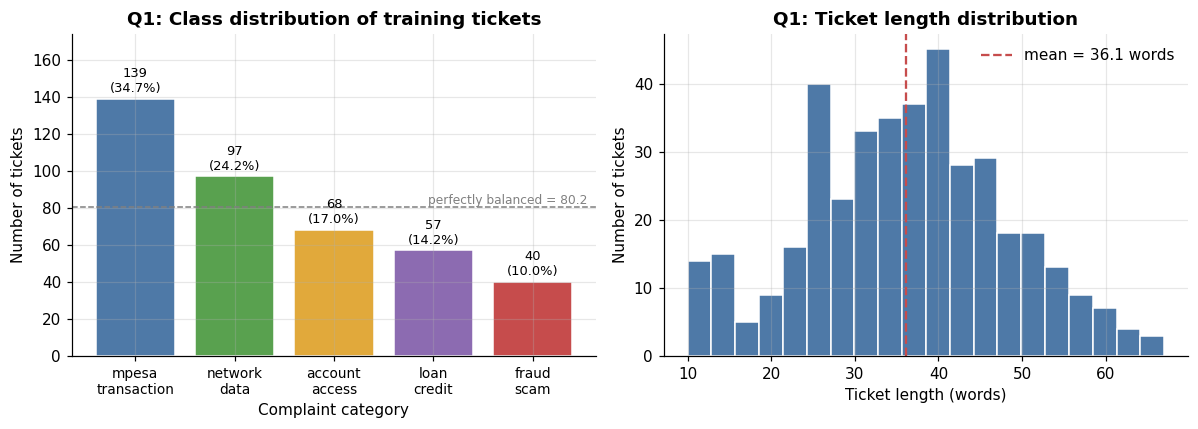

In [4]:
# Figure: class distribution (bar chart) and ticket-length distribution.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

order = dist.index.tolist()
axes[0].bar(range(len(order)), dist["n_tickets"].values,
            color=[PALETTE[c] for c in order], edgecolor="white")
axes[0].set_xticks(range(len(order)))
axes[0].set_xticklabels([c.replace("_", "\n") for c in order], fontsize=9)
axes[0].set_title("Q1: Class distribution of training tickets", fontweight="bold")
axes[0].set_xlabel("Complaint category")
axes[0].set_ylabel("Number of tickets")
for i, (n, p) in enumerate(zip(dist["n_tickets"], dist["percent"])):
    axes[0].text(i, n + 2, f"{n}\n({p}%)", ha="center", va="bottom", fontsize=8.5)
axes[0].axhline(len(train) / 5, ls="--", lw=1, color="grey")
axes[0].text(len(order) - 0.45, len(train) / 5 + 2,
             f"perfectly balanced = {len(train)/5:.1f}",
             ha="right", fontsize=8, color="grey")
axes[0].set_ylim(0, dist["n_tickets"].max() * 1.25)

axes[1].hist(train["n_words"], bins=20, color="#4E79A7", edgecolor="white")
axes[1].axvline(train["n_words"].mean(), color="#C64C4C", ls="--", lw=1.5,
                label=f"mean = {train['n_words'].mean():.1f} words")
axes[1].set_title("Q1: Ticket length distribution", fontweight="bold")
axes[1].set_xlabel("Ticket length (words)")
axes[1].set_ylabel("Number of tickets")
axes[1].legend(frameon=False)

save_fig("q1_class_distribution.png")
plt.show()

### Q2. Three example tickets and what makes classification hard [3 marks]

In [5]:
# Select illustrative tickets reproducibly, from three different categories,
# by searching for the three difficulties we want to evidence.
SWAHILI_MARKERS = ["nilituma", "nimenunua", "nimesahau", "nimeshindwa",
                   "naomba", "mkopo", "pesa", "simu", "lakini"]

def has_typo(t):
    return bool(re.search(r"\b(teh|transcation|pls|msg|coz|ur)\b", t.lower()))

def has_swahili(t):
    return any(w in t.lower() for w in SWAHILI_MARKERS)

def n_sentences(t):
    return len([s for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s.strip()])

picks, used = [], set()
for label, test in [("typos / SMS shorthand", lambda r: has_typo(r.complaint_text)),
                    ("Kiswahili / Sheng code-switching", lambda r: has_swahili(r.complaint_text)),
                    ("several issues in one ticket", lambda r: n_sentences(r.complaint_text) >= 4)]:
    for r in train.itertuples():
        if r.category not in used and test(r):
            picks.append((label, r)); used.add(r.category); break

for label, r in picks:
    print("=" * 100)
    print(f"{r.ticket_id}  |  category = {r.category}  |  "
          f"{r.n_words} words  |  {n_sentences(r.complaint_text)} sentences")
    print(f"illustrates: {label}")
    print("-" * 100)
    print(r.complaint_text)
print("=" * 100)

results["q2_examples"] = [
    {"label": l, "ticket_id": r.ticket_id, "category": r.category,
     "text": r.complaint_text, "n_words": int(r.n_words),
     "n_sentences": n_sentences(r.complaint_text)}
    for l, r in picks
]

T0005  |  category = account_access  |  19 words  |  2 sentences
illustrates: typos / SMS shorthand
----------------------------------------------------------------------------------------------------
I want to update my registered name coz it is spelt incorrectly on my profile. Please assist me urgently.
T0004  |  category = mpesa_transaction  |  22 words  |  2 sentences
illustrates: Kiswahili / Sheng code-switching
----------------------------------------------------------------------------------------------------
Fuliza amount was deducted automatically when I deposited money, please explain. My M-Pesa statement shows a transaction I do not remember making.
T0009  |  category = network_data  |  49 words  |  4 sentences
illustrates: several issues in one ticket
----------------------------------------------------------------------------------------------------
Nimenunua bundles za KES 15,000 lakini hazijaingia kwa simu yangu. My internet bundles finished within an hour even though I 

In [6]:
# Quantify each difficulty across the whole training set, so the claims in the
# write-up are backed by counts rather than by impressions.
tokens_all = [w for t in train["complaint_text"] for w in re.findall(r"[a-z'\-]+", t.lower())]
tok_counts = Counter(tokens_all)

print("1. TYPOS AND SMS SHORTHAND (deliberate noise on top of correct spellings)")
typo_pairs = [("teh", "the"), ("transcation", "transaction"), ("pls", "please"),
              ("msg", "message"), ("coz", "because"), ("ur", "your")]
for bad, good in typo_pairs:
    print(f"   '{bad}' x{tok_counts[bad]:<4} vs correct form '{good}' x{tok_counts[good]}")
n_typo = int(train["complaint_text"].apply(has_typo).sum())
print(f"   -> {n_typo}/{len(train)} tickets ({n_typo/len(train)*100:.1f}%) contain at "
      f"least one misspelling or abbreviation")

print("\n2. KISWAHILI / SHENG CODE-SWITCHING")
sw_present = [(w, tok_counts[w]) for w in
              ["nimeshindwa", "kuelewa", "kinachoendelea", "nilituma", "pesa", "lakini",
               "sijarudishiwa", "nimenunua", "bundles", "hazijaingia", "nimesahau",
               "akaunti", "imefungwa", "naomba", "mkopo", "simu", "yangu"]
              if tok_counts[w]]
print("   " + ", ".join(f"{w} x{n}" for w, n in sw_present))
n_sw = int(train["complaint_text"].apply(has_swahili).sum())
print(f"   -> {n_sw}/{len(train)} tickets ({n_sw/len(train)*100:.1f}%) mix English with "
      f"Kiswahili/Sheng")

print("\n3. SEVERAL ISSUES IN ONE TICKET")
sent_dist = train["complaint_text"].apply(n_sentences).value_counts().sort_index()
print("   sentences per ticket: " +
      ", ".join(f"{k} -> {v} tickets" for k, v in sent_dist.items()))
n_multi = int((train["complaint_text"].apply(n_sentences) >= 3).sum())
print(f"   -> {n_multi}/{len(train)} tickets ({n_multi/len(train)*100:.1f}%) contain 3 or "
      f"more sentences, often about different problems, but carry ONE label")

print("\n4. SHARED BOILERPLATE THAT CARRIES NO SIGNAL")
boiler = ["please assist me urgently", "kindly respond as soon as possible",
          "nimeshindwa kuelewa kinachoendelea", "i have been your customer for many years",
          "this is very frustrating"]
for b in boiler:
    mask = train["complaint_text"].str.lower().str.contains(b, regex=False)
    spread = train.loc[mask, "category"].nunique()
    print(f"   \"{b}\" appears in {int(mask.sum()):3d} tickets spanning {spread}/5 categories")

print("\n5. INCONSISTENT CASING")
n_lower = int((train["complaint_text"] == train["complaint_text"].str.lower()).sum())
print(f"   {n_lower}/{len(train)} tickets are entirely lower-case, the rest are "
      f"sentence-cased -> raw tokens like 'The' and 'the' would otherwise differ")

results["q2_counts"] = {
    "pct_typo": round(n_typo / len(train) * 100, 1),
    "pct_swahili": round(n_sw / len(train) * 100, 1),
    "pct_multi_sentence": round(n_multi / len(train) * 100, 1),
    "n_lowercase": n_lower,
    "typo_pairs": {b: [int(tok_counts[b]), int(tok_counts[g])] for b, g in typo_pairs},
    "swahili_tokens": {w: int(n) for w, n in sw_present},
    "sentences_per_ticket": {int(k): int(v) for k, v in sent_dist.items()},
}

1. TYPOS AND SMS SHORTHAND (deliberate noise on top of correct spellings)
   'teh' x41   vs correct form 'the' x886
   'transcation' x10   vs correct form 'transaction' x118
   'pls' x15   vs correct form 'please' x140
   'msg' x22   vs correct form 'message' x88
   'coz' x7    vs correct form 'because' x21
   'ur' x13   vs correct form 'your' x48
   -> 91/401 tickets (22.7%) contain at least one misspelling or abbreviation

2. KISWAHILI / SHENG CODE-SWITCHING
   nimeshindwa x35, kuelewa x35, kinachoendelea x35, nilituma x22, pesa x35, lakini x40, sijarudishiwa x22, nimenunua x18, bundles x45, hazijaingia x18, nimesahau x21, akaunti x21, imefungwa x21, naomba x14, mkopo x14, simu x31, yangu x39
   -> 162/401 tickets (40.4%) mix English with Kiswahili/Sheng

3. SEVERAL ISSUES IN ONE TICKET
   sentences per ticket: 1 -> 26 tickets, 2 -> 76 tickets, 3 -> 165 tickets, 4 -> 104 tickets, 5 -> 30 tickets
   -> 299/401 tickets (74.6%) contain 3 or more sentences, often about different problems

### Q3. Why the majority-class baseline flatters itself [3 marks]

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

X_text = train["complaint_text"].values
y = train["category"].values

dummy = DummyClassifier(strategy="most_frequent", random_state=SEED).fit(X_text, y)
y_dummy = dummy.predict(X_text)

acc_d = accuracy_score(y, y_dummy)
mf1_d = f1_score(y, y_dummy, average="macro", zero_division=0)
wf1_d = f1_score(y, y_dummy, average="weighted", zero_division=0)

majority_class = train["category"].mode()[0]
print(f"Baseline: always predict the biggest class ('{majority_class}')\n")
print(f"  Accuracy    on training data : {acc_d:.4f}  ({acc_d*100:.2f}%)")
print(f"  Macro-F1    on training data : {mf1_d:.4f}")
print(f"  Weighted-F1 on training data : {wf1_d:.4f}")
print(f"\nThat accuracy is exactly the share of the biggest class: "
      f"{dist['n_tickets'].iloc[0]}/{len(train)} = "
      f"{dist['n_tickets'].iloc[0]/len(train):.4f}")

print("\nPer-class recall of this baseline:")
for cat in dist.index:
    rec = recall_score(y, y_dummy, labels=[cat], average="macro", zero_division=0)
    print(f"  {cat:20s} recall = {rec:.2f}")

print("\nFull classification report for the majority-class baseline:")
print(classification_report(y, y_dummy, zero_division=0, digits=3))

results["baseline_acc"] = float(acc_d)
results["baseline_macro_f1"] = float(mf1_d)
results["baseline_weighted_f1"] = float(wf1_d)
results["majority_class"] = train["category"].mode()[0]

Baseline: always predict the biggest class ('mpesa_transaction')

  Accuracy    on training data : 0.3466  (34.66%)
  Macro-F1    on training data : 0.1030
  Weighted-F1 on training data : 0.1785

That accuracy is exactly the share of the biggest class: 139/401 = 0.3466

Per-class recall of this baseline:
  mpesa_transaction    recall = 1.00
  network_data         recall = 0.00
  account_access       recall = 0.00
  loan_credit          recall = 0.00
  fraud_scam           recall = 0.00

Full classification report for the majority-class baseline:
                   precision    recall  f1-score   support

   account_access      0.000     0.000     0.000        68
       fraud_scam      0.000     0.000     0.000        40
      loan_credit      0.000     0.000     0.000        57
mpesa_transaction      0.347     1.000     0.515       139
     network_data      0.000     0.000     0.000        97

         accuracy                          0.347       401
        macro avg      0.069    

---
## Part B — Preprocessing (20 marks)

### Q4. A configurable preprocessing function [6 marks]

In [8]:
STEMMER = PorterStemmer()
LEMMATISER = WordNetLemmatizer()

# A small hand-built Kiswahili/Sheng function-word list. NLTK ships no Swahili
# stop-word list (see the check below), which is itself part of the Q6 answer.
SW_STOPWORDS = {
    "na", "ya", "za", "wa", "kwa", "la", "ni", "si", "kama", "lakini", "sana",
    "tu", "pia", "hii", "hiyo", "ile", "hilo", "yangu", "yako", "yake", "bado",
    "sasa", "tena", "kuwa", "ili", "kwenye", "juu", "chini",
}
print("Does NLTK provide a Swahili stop-word list? ",
      "swahili" in stopwords.fileids())

PUNCT_TABLE = str.maketrans({c: " " for c in string.punctuation})


def preprocess(text, remove_stopwords=False, normalise=None,
               keep_numbers=False, protect_negation=False,
               swahili_stopwords=False, return_tokens=False):
    """Clean one complaint ticket.

    Steps, in order:
      1. lower-case
      2. remove numbers      (unless keep_numbers=True)
      3. remove punctuation
      4. tokenise with NLTK word_tokenize
      5. drop stop words     (optional; optionally keeping negation words)
      6. stem or lemmatise   (optional)

    normalise: None | "stem" | "lemma"
    """
    t = text.lower()

    if not keep_numbers:
        # Strip digits, including thousands separators such as "1,200".
        t = re.sub(r"\d[\d,\.]*", " ", t)

    t = t.translate(PUNCT_TABLE)          # punctuation -> space
    tokens = word_tokenize(t)
    tokens = [w for w in tokens if w.isalpha() or (keep_numbers and w.isalnum())]

    if remove_stopwords:
        drop = set(EN_STOPWORDS)
        if protect_negation:
            drop -= {"not", "no", "nor", "never", "cannot"}
        if swahili_stopwords:
            drop |= SW_STOPWORDS
        tokens = [w for w in tokens if w not in drop]

    if normalise == "stem":
        tokens = [STEMMER.stem(w) for w in tokens]
    elif normalise == "lemma":
        tokens = [LEMMATISER.lemmatize(w) for w in tokens]

    return tokens if return_tokens else " ".join(tokens)


# The four required settings.
SETTINGS = {
    "S1 none (clean + tokenise only)": dict(remove_stopwords=False, normalise=None),
    "S2 stop words only":              dict(remove_stopwords=True,  normalise=None),
    "S3 stop words + stemming":        dict(remove_stopwords=True,  normalise="stem"),
    "S4 stop words + lemmatisation":   dict(remove_stopwords=True,  normalise="lemma"),
}

# Show before/after on one ticket that contains a typo, a number and Kiswahili.
demo_mask = (train["complaint_text"].str.lower().str.contains("nilituma|nimenunua|nimesahau")
             & train["complaint_text"].str.contains(r"\d"))
demo = train[demo_mask].iloc[0]

print("=" * 100)
print(f"BEFORE  —  {demo.ticket_id}  (category = {demo.category})")
print("=" * 100)
print(demo.complaint_text)
for name, cfg in SETTINGS.items():
    out = preprocess(demo.complaint_text, **cfg)
    print("\n" + "=" * 100)
    print(f"AFTER  —  {name}   ({len(out.split())} tokens)")
    print("=" * 100)
    print(out)

results["q4_demo"] = {
    "ticket_id": demo.ticket_id, "category": demo.category,
    "before": demo.complaint_text,
    "after": {name: preprocess(demo.complaint_text, **cfg)
              for name, cfg in SETTINGS.items()},
}

Does NLTK provide a Swahili stop-word list?  False
BEFORE  —  T0009  (category = network_data)
Nimenunua bundles za KES 15,000 lakini hazijaingia kwa simu yangu. My internet bundles finished within an hour even though I was not browsing. The 4G network is down at our office and technicians have not come on Friday. This is very frustrating, I have called customer care three times.

AFTER  —  S1 none (clean + tokenise only)   (48 tokens)
nimenunua bundles za kes lakini hazijaingia kwa simu yangu my internet bundles finished within an hour even though i was not browsing the g network is down at our office and technicians have not come on friday this is very frustrating i have called customer care three times

AFTER  —  S2 stop words only   (29 tokens)
nimenunua bundles za kes lakini hazijaingia kwa simu yangu internet bundles finished within hour even though browsing g network office technicians come friday frustrating called customer care three times

AFTER  —  S3 stop words + stemming  


AFTER  —  S4 stop words + lemmatisation   (29 tokens)
nimenunua bundle za kes lakini hazijaingia kwa simu yangu internet bundle finished within hour even though browsing g network office technician come friday frustrating called customer care three time


### Q5. Vocabulary size under each setting [4 marks]

In [9]:
vocab_rows = []
corpora = {}
for name, cfg in SETTINGS.items():
    docs = [preprocess(t, **cfg) for t in train["complaint_text"]]
    corpora[name] = docs
    toks = [w for d in docs for w in d.split()]
    vocab = set(toks)
    vocab_rows.append({
        "setting": name,
        "unique_tokens": len(vocab),
        "total_tokens": len(toks),
        "mean_tokens_per_ticket": round(len(toks) / len(docs), 1),
        "type_token_ratio": round(len(vocab) / len(toks), 4),
    })

vocab_tbl = pd.DataFrame(vocab_rows).set_index("setting")
base = vocab_tbl["unique_tokens"].iloc[0]
vocab_tbl["vs_S1_tokens"] = vocab_tbl["unique_tokens"] - base
vocab_tbl["vs_S1_percent"] = ((vocab_tbl["unique_tokens"] - base) / base * 100).round(1)
print("Vocabulary size under the four preprocessing settings")
print(vocab_tbl.to_string())

print(f"\nStop-word removal alone drops "
      f"{base - vocab_tbl['unique_tokens'].iloc[1]} word types but removes "
      f"{vocab_tbl['total_tokens'].iloc[0] - vocab_tbl['total_tokens'].iloc[1]} tokens "
      f"({(1 - vocab_tbl['total_tokens'].iloc[1]/vocab_tbl['total_tokens'].iloc[0])*100:.1f}% "
      f"of all running words).")
print(f"Stemming shrinks the vocabulary to {vocab_tbl['unique_tokens'].iloc[2]} types "
      f"({vocab_tbl['vs_S1_percent'].iloc[2]:.1f}% vs S1); "
      f"lemmatisation only to {vocab_tbl['unique_tokens'].iloc[3]} types "
      f"({vocab_tbl['vs_S1_percent'].iloc[3]:.1f}% vs S1).")

# Evidence for *why* stemming shrinks more: show the merges it performs.
print("\nWhy stemming shrinks more — word types collapsed onto one stem:")
stem_groups = defaultdict(set)
for w in set(w for d in corpora["S2 stop words only"] for w in d.split()):
    stem_groups[STEMMER.stem(w)].add(w)
merged = {s: ws for s, ws in stem_groups.items() if len(ws) > 1}
for s, ws in sorted(merged.items(), key=lambda kv: -len(kv[1]))[:12]:
    print(f"   {s:14s} <- {sorted(ws)}")
print(f"   ({len(merged)} stems absorb more than one word type)")

lem_groups = defaultdict(set)
for w in set(w for d in corpora["S2 stop words only"] for w in d.split()):
    lem_groups[LEMMATISER.lemmatize(w)].add(w)
lmerged = {s: ws for s, ws in lem_groups.items() if len(ws) > 1}
print(f"\nLemmatisation merges only {len(lmerged)} groups, e.g.:")
for s, ws in sorted(lmerged.items(), key=lambda kv: -len(kv[1]))[:6]:
    print(f"   {s:14s} <- {sorted(ws)}")

results["q5_table"] = vocab_tbl.reset_index().to_dict("records")
results["q5_n_stem_merges"] = len(merged)
results["q5_n_lemma_merges"] = len(lmerged)
results["q5_stem_examples"] = {s: sorted(ws) for s, ws in
                               sorted(merged.items(), key=lambda kv: -len(kv[1]))[:8]}

Vocabulary size under the four preprocessing settings
                                 unique_tokens  total_tokens  mean_tokens_per_ticket  type_token_ratio  vs_S1_tokens  vs_S1_percent
setting                                                                                                                            
S1 none (clean + tokenise only)            357         14500                    36.2            0.0246             0            0.0
S2 stop words only                         304          8587                    21.4            0.0354           -53          -14.8
S3 stop words + stemming                   280          8587                    21.4            0.0326           -77          -21.6
S4 stop words + lemmatisation              295          8587                    21.4            0.0344           -62          -17.4

Stop-word removal alone drops 53 word types but removes 5913 tokens (40.8% of all running words).
Stemming shrinks the vocabulary to 280 types (-21.6% vs

### Q6. Code-switching: what English tools do to Kiswahili/Sheng [6 marks]

In [10]:
SW_WORDS = ["nimeshindwa", "nilituma", "nimenunua", "nimesahau", "naomba",
            "pesa", "mkopo", "simu", "akaunti", "bundles", "imefungwa",
            "sijarudishiwa", "hazijaingia", "lakini", "yangu", "kuelewa",
            "kinachoendelea", "nikilipa", "mapema", "kuongezewa"]

rows = []
for w in SW_WORDS:
    if not tok_counts[w]:
        continue
    rows.append({
        "kiswahili_word": w,
        "count": tok_counts[w],
        "gloss": {
            "nimeshindwa": "I have failed / I am unable",
            "nilituma": "I sent", "nimenunua": "I have bought",
            "nimesahau": "I have forgotten", "naomba": "I request",
            "pesa": "money", "mkopo": "loan", "simu": "phone",
            "akaunti": "account", "bundles": "data bundles (Sheng loan-word)",
            "imefungwa": "it has been locked", "sijarudishiwa": "I have not been refunded",
            "hazijaingia": "they have not arrived", "lakini": "but",
            "yangu": "my", "kuelewa": "to understand",
            "kinachoendelea": "what is going on", "nikilipa": "while I pay",
            "mapema": "early", "kuongezewa": "to be increased",
        }.get(w, ""),
        "in_EN_stoplist": w in EN_STOPWORDS,
        "after_stem": STEMMER.stem(w),
        "after_lemma": LEMMATISER.lemmatize(w),
    })

sw_tbl = pd.DataFrame(rows)
sw_tbl["stem_changed"] = sw_tbl["kiswahili_word"] != sw_tbl["after_stem"]
sw_tbl["lemma_changed"] = sw_tbl["kiswahili_word"] != sw_tbl["after_lemma"]
print("Kiswahili/Sheng words in the training data and what English tools do to them")
print(sw_tbl.to_string(index=False))

print(f"\nSummary")
print(f"  words caught by the English stop-word list : "
      f"{int(sw_tbl['in_EN_stoplist'].sum())}/{len(sw_tbl)}")
print(f"  words changed by the Porter stemmer        : "
      f"{int(sw_tbl['stem_changed'].sum())}/{len(sw_tbl)}")
print(f"  words changed by the WordNet lemmatiser    : "
      f"{int(sw_tbl['lemma_changed'].sum())}/{len(sw_tbl)}")

# Kiswahili function words that English stop-word removal leaves behind.
print("\nKiswahili function words that survive English stop-word removal "
      "(they are 'the/of/but' of Kiswahili, yet stay in the vocabulary):")
for w in ["na", "ya", "za", "kwa", "lakini", "tu", "ni"]:
    if tok_counts[w]:
        print(f"   '{w}' x{tok_counts[w]:<4} in English stop list? {w in EN_STOPWORDS}")

# A full sentence, before and after, to show the damage concretely.
sw_demo = train[train["complaint_text"].str.lower()
                .str.contains("nimenunua|nilituma")].iloc[0]
sent = [s for s in re.split(r"(?<=[.!?])\s+", sw_demo.complaint_text)
        if re.search(r"nimenunua|nilituma", s.lower())][0]
print("\n" + "=" * 100)
print("Before :", sent)
print("S2 (stop words only)       :", preprocess(sent, remove_stopwords=True))
print("S3 (stop words + stemming) :", preprocess(sent, remove_stopwords=True, normalise="stem"))
print("S4 (stop words + lemma)    :", preprocess(sent, remove_stopwords=True, normalise="lemma"))
print("With a Kiswahili stop list :", preprocess(sent, remove_stopwords=True,
                                                 swahili_stopwords=True))
print("=" * 100)

results["q6_table"] = sw_tbl.to_dict("records")
results["q6_sentence_demo"] = {
    "ticket_id": sw_demo.ticket_id, "before": sent,
    "S2": preprocess(sent, remove_stopwords=True),
    "S3": preprocess(sent, remove_stopwords=True, normalise="stem"),
    "S4": preprocess(sent, remove_stopwords=True, normalise="lemma"),
    "with_sw_stoplist": preprocess(sent, remove_stopwords=True, swahili_stopwords=True),
}
results["q6_counts"] = {
    "n_words": len(sw_tbl),
    "n_in_en_stoplist": int(sw_tbl["in_EN_stoplist"].sum()),
    "n_stem_changed": int(sw_tbl["stem_changed"].sum()),
    "n_lemma_changed": int(sw_tbl["lemma_changed"].sum()),
}

Kiswahili/Sheng words in the training data and what English tools do to them
kiswahili_word  count                          gloss  in_EN_stoplist     after_stem    after_lemma  stem_changed  lemma_changed
   nimeshindwa     35    I have failed / I am unable           False    nimeshindwa    nimeshindwa         False          False
      nilituma     22                         I sent           False       nilituma       nilituma         False          False
     nimenunua     18                  I have bought           False      nimenunua      nimenunua         False          False
     nimesahau     21               I have forgotten           False      nimesahau      nimesahau         False          False
        naomba     14                      I request           False         naomba         naomba         False          False
          pesa     35                          money           False           pesa           pesa         False          False
         mkopo     14      

### Q7. A preprocessing step that could HURT this task [4 marks]

Candidate: **removing numbers**, because `4g` / `3g` are network vocabulary, and
**removing English stop words**, because the list contains the negation words
`not`, `no`, `nor`, `never` and these tickets are *about* things not happening.
Both claims are tested below with 5-fold cross-validation.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# First, the direct evidence: which signal-bearing tokens does digit-removal destroy?
print("Tokens that disappear or change when numbers are stripped")
for probe in ["4g", "3g"]:
    n_raw = sum(1 for t in train["complaint_text"] if probe in t.lower())
    print(f"   '{probe}' appears in {n_raw} tickets; after digit removal it becomes "
          f"'{preprocess(f'the {probe} network is down')}'")
net = train[train["complaint_text"].str.lower().str.contains("4g|3g")]
print(f"   tickets containing 4g/3g: {len(net)}, "
      f"{(net['category'] == 'network_data').mean()*100:.0f}% of them are network_data")

print("\nNegation words the English stop-word list removes, and where they matter:")
for ng in ["not", "no", "never", "cannot"]:
    mask = train["complaint_text"].str.lower().str.contains(rf"\b{ng}\b")
    print(f"   '{ng}':{'':<3} in {int(mask.sum()):3d} tickets ({mask.mean()*100:4.0f}%) "
          f"| in NLTK stop list? {ng in EN_STOPWORDS}")

ex = train[train["complaint_text"].str.lower()
           .str.contains("did not reflect|never received|not been credited")].iloc[0]
sent_neg = [s for s in re.split(r"(?<=[.!?])\s+", ex.complaint_text)
            if re.search(r"did not reflect|never received|not been credited", s.lower())][0]
print(f"\n   Before : {sent_neg}")
print(f"   After S2: {preprocess(sent_neg, remove_stopwords=True)}")
print("   -> the complaint 'the payment did NOT reflect' and a hypothetical "
      "'the payment did reflect' collapse to the same tokens.")

Tokens that disappear or change when numbers are stripped
   '4g' appears in 16 tickets; after digit removal it becomes 'the g network is down'
   '3g' appears in 0 tickets; after digit removal it becomes 'the g network is down'
   tickets containing 4g/3g: 16, 100% of them are network_data

Negation words the English stop-word list removes, and where they matter:
   'not':    in 170 tickets (  42%) | in NLTK stop list? True
   'no':    in  50 tickets (  12%) | in NLTK stop list? True
   'never':    in  69 tickets (  17%) | in NLTK stop list? False
   'cannot':    in  41 tickets (  10%) | in NLTK stop list? False

   Before : I paid the till number but the merchant says the payment did not reflect.
   After S2: paid till number merchant says payment reflect
   -> the complaint 'the payment did NOT reflect' and a hypothetical 'the payment did reflect' collapse to the same tokens.


In [12]:
# Controlled experiment for Q7. One factor changed at a time, everything else fixed.
def cv_macro_f1(docs, labels=y, clf=None, vec=None):
    """5-fold stratified CV macro-F1 for a (vectoriser, classifier) pair."""
    vec = vec or TfidfVectorizer(token_pattern=r"(?u)\b\w[\w'\-]+\b", min_df=1)
    clf = clf or LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)
    pipe = make_pipeline(vec, clf)
    s = cross_val_score(pipe, docs, labels, cv=CV, scoring="f1_macro", n_jobs=1)
    return s

exp7 = {}
# (a) numbers removed vs kept  — stop words left ON in both arms
exp7["numbers removed (and stop words removed)"] = cv_macro_f1(
    [preprocess(t, remove_stopwords=True, keep_numbers=False) for t in train["complaint_text"]])
exp7["numbers kept (and stop words removed)"] = cv_macro_f1(
    [preprocess(t, remove_stopwords=True, keep_numbers=True) for t in train["complaint_text"]])
# (b) stop words removed vs kept — numbers removed in both arms
exp7["stop words removed"] = cv_macro_f1(
    [preprocess(t, remove_stopwords=True) for t in train["complaint_text"]])
exp7["stop words kept"] = cv_macro_f1(
    [preprocess(t, remove_stopwords=False) for t in train["complaint_text"]])
# (c) stop words removed but negation protected
exp7["stop words removed, negation protected"] = cv_macro_f1(
    [preprocess(t, remove_stopwords=True, protect_negation=True) for t in train["complaint_text"]])

tbl7 = pd.DataFrame({k: {"mean_macro_f1": v.mean(), "std": v.std()}
                     for k, v in exp7.items()}).T.round(4)
print("Q7 experiment — LinearSVC on TF-IDF, 5-fold stratified CV, only one factor changed")
print(tbl7.to_string())

d_num = exp7["numbers kept (and stop words removed)"] - exp7["numbers removed (and stop words removed)"]
d_sw = exp7["stop words kept"] - exp7["stop words removed"]
print(f"\nKeeping numbers      : {d_num.mean():+.4f} macro-F1 "
      f"(paired per-fold std {d_num.std():.4f})")
print(f"Keeping stop words   : {d_sw.mean():+.4f} macro-F1 "
      f"(paired per-fold std {d_sw.std():.4f})")

results["q7_table"] = tbl7.reset_index().rename(columns={"index": "setting"}).to_dict("records")
results["q7_deltas"] = {
    "keep_numbers_delta": float(d_num.mean()), "keep_numbers_std": float(d_num.std()),
    "keep_stopwords_delta": float(d_sw.mean()), "keep_stopwords_std": float(d_sw.std()),
}
results["q7_negation_example"] = {"before": sent_neg,
                                  "after": preprocess(sent_neg, remove_stopwords=True)}
results["q7_4g_share_network"] = float((net["category"] == "network_data").mean())
results["q7_n_4g_tickets"] = int(len(net))

Q7 experiment — LinearSVC on TF-IDF, 5-fold stratified CV, only one factor changed
                                          mean_macro_f1     std
numbers removed (and stop words removed)         0.9199  0.0285
numbers kept (and stop words removed)            0.9184  0.0292
stop words removed                               0.9199  0.0285
stop words kept                                  0.9176  0.0252
stop words removed, negation protected           0.9165  0.0274

Keeping numbers      : -0.0014 macro-F1 (paired per-fold std 0.0029)
Keeping stop words   : -0.0022 macro-F1 (paired per-fold std 0.0096)


---
## Part C — Representation (15 marks)

### Q8. Bag-of-Words and TF-IDF: shape, sparsity, top terms [5 marks]

In [13]:
# ---------------------------------------------------------------------------
# The preprocessing used for every model from here on, defined ONCE so the
# training and test sets can never be processed differently.
#
# Justification from the Q7 experiment: all five arms scored within one standard
# deviation of each other, so accuracy does not decide this. We therefore choose
# on the two grounds that the experiment did expose:
#   * stop-word removal, because it produces a far more interpretable feature
#     space (Q8) at no measurable cost;
#   * negation protected, because Q7 showed "did not reflect" and "did reflect"
#     otherwise collapse to the same tokens.
# ---------------------------------------------------------------------------
MODEL_PREPROC = dict(remove_stopwords=True, protect_negation=True, normalise=None)

docs_model = [preprocess(t, **MODEL_PREPROC) for t in train["complaint_text"]]
print(f"Model input: {len(docs_model)} documents, preprocessing = {MODEL_PREPROC}")
print(f"example -> {docs_model[0]}")

bow_vec = CountVectorizer(token_pattern=r"(?u)\b\w[\w'\-]+\b")
tfidf_vec = TfidfVectorizer(token_pattern=r"(?u)\b\w[\w'\-]+\b")
X_bow = bow_vec.fit_transform(docs_model)
X_tfidf = tfidf_vec.fit_transform(docs_model)

for nm, X, vec in [("Bag-of-Words", X_bow, bow_vec), ("TF-IDF", X_tfidf, tfidf_vec)]:
    sparsity = 1.0 - X.nnz / (X.shape[0] * X.shape[1])
    print(f"{nm}")
    print(f"   matrix shape      : {X.shape[0]} tickets x {X.shape[1]} features")
    print(f"   stored non-zeros  : {X.nnz:,} of {X.shape[0]*X.shape[1]:,} cells")
    print(f"   sparsity          : {sparsity*100:.2f}% zeros "
          f"(density {100-sparsity*100:.2f}%)")
    print(f"   mean non-zeros/row: {X.nnz/X.shape[0]:.1f}")

results["q8_bow_shape"] = list(X_bow.shape)
results["q8_tfidf_shape"] = list(X_tfidf.shape)
results["q8_bow_sparsity"] = float(1 - X_bow.nnz / (X_bow.shape[0]*X_bow.shape[1]))
results["q8_tfidf_sparsity"] = float(1 - X_tfidf.nnz / (X_tfidf.shape[0]*X_tfidf.shape[1]))
results["q8_nnz_per_row"] = float(X_tfidf.nnz / X_tfidf.shape[0])

Model input: 401 documents, preprocessing = {'remove_stopwords': True, 'protect_negation': True, 'normalise': None}
example -> message reference ready paid till number merchant says payment not reflect please reverse kes sent wrong paybill message reference
Bag-of-Words
   matrix shape      : 401 tickets x 305 features
   stored non-zeros  : 8,548 of 122,305 cells
   sparsity          : 93.01% zeros (density 6.99%)
   mean non-zeros/row: 21.3
TF-IDF
   matrix shape      : 401 tickets x 305 features
   stored non-zeros  : 8,548 of 122,305 cells
   sparsity          : 93.01% zeros (density 6.99%)
   mean non-zeros/row: 21.3


In [14]:
# Five highest-weighted terms per category.
# Method 1: highest mean TF-IDF weight inside each class.
feat = np.array(tfidf_vec.get_feature_names_out())
print("Top 5 terms per category by MEAN TF-IDF WEIGHT within the class")
top_tfidf = {}
for cat in CATEGORIES:
    m = X_tfidf[y == cat].mean(axis=0).A1
    idx = m.argsort()[::-1][:5]
    top_tfidf[cat] = [(feat[i], round(float(m[i]), 4)) for i in idx]
    print(f"   {cat:20s} " + ", ".join(f"{feat[i]} ({m[i]:.3f})" for i in idx))

# Method 2: largest one-vs-rest logistic-regression coefficients (more
# discriminative: it rewards terms that are frequent in the class AND rare elsewhere).
lr_probe = LogisticRegression(max_iter=2000, class_weight="balanced",
                              random_state=SEED).fit(X_tfidf, y)
print("\nTop 5 terms per category by LOGISTIC-REGRESSION COEFFICIENT (discriminative)")
top_coef = {}
for i, cat in enumerate(lr_probe.classes_):
    idx = lr_probe.coef_[i].argsort()[::-1][:5]
    top_coef[cat] = [(feat[j], round(float(lr_probe.coef_[i][j]), 3)) for j in idx]
    print(f"   {cat:20s} " + ", ".join(f"{feat[j]} ({lr_probe.coef_[i][j]:+.2f})" for j in idx))

results["q8_top_tfidf"] = top_tfidf
results["q8_top_coef"] = top_coef

Top 5 terms per category by MEAN TF-IDF WEIGHT within the class
   mpesa_transaction    transaction (0.102), not (0.091), paybill (0.079), kes (0.079), pesa (0.079)
   network_data         bundles (0.077), network (0.076), calls (0.071), keep (0.069), data (0.068)
   account_access       pin (0.082), account (0.074), app (0.072), phone (0.070), need (0.067)
   loan_credit          loan (0.217), outstanding (0.073), full (0.073), still (0.073), repaid (0.073)
   fraud_scam           someone (0.130), fake (0.094), customers (0.091), impersonating (0.091), collecting (0.091)

Top 5 terms per category by LOGISTIC-REGRESSION COEFFICIENT (discriminative)
   account_access       app (+1.01), update (+0.98), phone (+0.96), pin (+0.92), need (+0.86)
   fraud_scam           someone (+1.59), fake (+1.20), text (+1.07), clicked (+1.07), link (+1.07)
   loan_credit          loan (+2.79), disclosed (+1.05), interest (+1.05), approved (+0.97), reached (+0.97)
   mpesa_transaction    transaction (+1.4

### Q9. Unigrams vs unigrams + bigrams [4 marks]

In [15]:
s_uni = cv_macro_f1(docs_model,
                    vec=TfidfVectorizer(ngram_range=(1, 1),
                                        token_pattern=r"(?u)\b\w[\w'\-]+\b"))
s_bi = cv_macro_f1(docs_model,
                   vec=TfidfVectorizer(ngram_range=(1, 2),
                                       token_pattern=r"(?u)\b\w[\w'\-]+\b"))

v_uni = TfidfVectorizer(ngram_range=(1, 1), token_pattern=r"(?u)\b\w[\w'\-]+\b").fit(docs_model)
v_bi = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w[\w'\-]+\b").fit(docs_model)
print(f"unigrams only      : {len(v_uni.vocabulary_):,} features, "
      f"macro-F1 = {s_uni.mean():.4f} +/- {s_uni.std():.4f}")
print(f"unigrams + bigrams : {len(v_bi.vocabulary_):,} features, "
      f"macro-F1 = {s_bi.mean():.4f} +/- {s_bi.std():.4f}")
d_ng = s_bi - s_uni
print(f"difference         : {d_ng.mean():+.4f} (paired per-fold std {d_ng.std():.4f})")

# Which bigrams are actually informative? Fit LR on the bigram space and look at
# the highest-weighted two-word features per class.
Xb = v_bi.transform(docs_model)
fb = np.array(v_bi.get_feature_names_out())
lrb = LogisticRegression(max_iter=2000, class_weight="balanced",
                         random_state=SEED).fit(Xb, y)
print("\nHighest-weighted BIGRAM features per category")
top_bigrams = {}
for i, cat in enumerate(lrb.classes_):
    order = lrb.coef_[i].argsort()[::-1]
    bigs = [(fb[j], round(float(lrb.coef_[i][j]), 3))
            for j in order if " " in fb[j]][:4]
    top_bigrams[cat] = bigs
    print(f"   {cat:20s} " + ", ".join(f"'{b}' ({w:+.2f})" for b, w in bigs))

# The headline example: "till number" vs the unigram "number".
print("\nWhy a unigram alone misses it — the word 'number' on its own:")
for probe in ["till number", "wrong number", "number"]:
    mask = train["complaint_text"].str.lower().str.contains(probe, regex=False)
    share = (train.loc[mask, "category"].value_counts(normalize=True) * 100).round(0)
    print(f"   '{probe}' -> {int(mask.sum())} tickets | " +
          ", ".join(f"{k} {v:.0f}%" for k, v in share.items()))

results["q9"] = {
    "uni_features": len(v_uni.vocabulary_), "bi_features": len(v_bi.vocabulary_),
    "uni_mean": float(s_uni.mean()), "uni_std": float(s_uni.std()),
    "bi_mean": float(s_bi.mean()), "bi_std": float(s_bi.std()),
    "delta": float(d_ng.mean()), "delta_std": float(d_ng.std()),
    "top_bigrams": top_bigrams,
}
results["q9_number_probe"] = {
    probe: {"n": int(train["complaint_text"].str.lower().str.contains(probe, regex=False).sum()),
            "dist": (train.loc[train["complaint_text"].str.lower()
                     .str.contains(probe, regex=False), "category"]
                     .value_counts(normalize=True).mul(100).round(0).to_dict())}
    for probe in ["till number", "wrong number", "number"]
}

unigrams only      : 305 features, macro-F1 = 0.9165 +/- 0.0274
unigrams + bigrams : 1,448 features, macro-F1 = 0.9153 +/- 0.0325
difference         : -0.0013 (paired per-fold std 0.0198)



Highest-weighted BIGRAM features per category
   account_access       'incorrectly profile' (+0.63), 'spelt incorrectly' (+0.63), 'registered name' (+0.63), 'update registered' (+0.63)
   fraud_scam           'cash customers' (+0.74), 'collecting cash' (+0.74), 'someone impersonating' (+0.74), 'agent collecting' (+0.74)
   loan_credit          'interest mobile' (+0.76), 'loan looks' (+0.76), 'mobile loan' (+0.76), 'higher disclosed' (+0.76)
   mpesa_transaction    'not credited' (+0.54), 'electricity tokens' (+0.54), 'credited since' (+0.54), 'tokens not' (+0.54)
   network_data         'not come' (+0.68), 'office technicians' (+0.68), 'technicians not' (+0.68), 'network office' (+0.68)

Why a unigram alone misses it — the word 'number' on its own:
   'till number' -> 30 tickets | mpesa_transaction 90%, network_data 3%, fraud_scam 3%, loan_credit 3%
   'wrong number' -> 24 tickets | mpesa_transaction 88%, network_data 8%, loan_credit 4%
   'number' -> 64 tickets | mpesa_transaction 78

### Q10. Word2Vec on the tickets, GloVe, and averaged document vectors [6 marks]

In [16]:
from gensim.models import Word2Vec

# Tokenised corpus for Word2Vec: stop words kept, so context windows stay natural.
w2v_corpus = [preprocess(t, remove_stopwords=False, return_tokens=True)
              for t in train["complaint_text"]]

t0 = time.time()
w2v = Word2Vec(sentences=w2v_corpus, vector_size=100, window=5, min_count=2,
               sg=1, epochs=100, workers=1, seed=SEED)   # workers=1 -> reproducible
w2v_secs = time.time() - t0

print(f"Word2Vec (skip-gram) trained on {len(w2v_corpus)} tickets in {w2v_secs:.1f}s")
print(f"   corpus size      : {sum(len(d) for d in w2v_corpus):,} tokens")
print(f"   vocabulary       : {len(w2v.wv.index_to_key)} words (min_count=2)")
print(f"   vector dimension : {w2v.wv.vector_size}")

PROBE_WORDS = ["loan", "network", "fraudster", "pin", "pesa"]
print("\nFive nearest neighbours in the Word2Vec model trained on 401 tickets")
w2v_nn = {}
for w in PROBE_WORDS:
    if w in w2v.wv:
        nn = w2v.wv.most_similar(w, topn=5)
        w2v_nn[w] = [(a, round(float(b), 3)) for a, b in nn]
        print(f"   {w:11s} -> " + ", ".join(f"{a} ({b:.2f})" for a, b in nn))
    else:
        print(f"   {w:11s} -> not in vocabulary")

Word2Vec (skip-gram) trained on 401 tickets in 3.9s
   corpus size      : 14,500 tokens
   vocabulary       : 357 words (min_count=2)
   vector dimension : 100

Five nearest neighbours in the Word2Vec model trained on 401 tickets
   loan        -> disbursement (0.48), listed (0.47), still (0.46), restructure (0.45), what (0.45)
   network     -> coverage (0.68), down (0.67), g (0.62), area (0.61), there (0.54)
   fraudster   -> tricked (0.97), send (0.50), mtu (0.48), last (0.47), sending (0.46)
   pin         -> blocked (0.52), akaunti (0.52), asked (0.50), nimesahau (0.47), imefungwa (0.46)
   pesa        -> m (0.60), recipient (0.51), statement (0.51), nilituma (0.49), ime (0.43)


In [17]:
# GloVe for comparison (pre-trained on 6B words of Wikipedia + Gigaword).
glove = None
try:
    import gensim.downloader as api
    t0 = time.time()
    glove = api.load("glove-wiki-gigaword-100")
    print(f"GloVe loaded: {len(glove.index_to_key):,} vectors, dim {glove.vector_size} "
          f"({time.time()-t0:.0f}s)")
except Exception as exc:
    print(f"GloVe unavailable ({exc}); the notebook continues with Word2Vec only.")

glove_nn = {}
if glove is not None:
    print("\nSame probe words in GloVe (trained on 6 billion words of English)")
    for w in PROBE_WORDS:
        if w in glove.key_to_index:
            nn = glove.most_similar(w, topn=5)
            glove_nn[w] = [(a, round(float(b), 3)) for a, b in nn]
            print(f"   {w:11s} -> " + ", ".join(f"{a} ({b:.2f})" for a, b in nn))
        else:
            print(f"   {w:11s} -> NOT IN GloVe vocabulary")

    print("\nDomain and Kiswahili coverage — the cost of a generic English corpus:")
    probe_cov = ["mpesa", "m-pesa", "paybill", "fuliza", "mkopo", "pesa", "simu",
                 "akaunti", "nimeshindwa", "sijarudishiwa", "safaricom"]
    for w in probe_cov:
        inw = w in w2v.wv
        ing = glove is not None and w in glove.key_to_index
        print(f"   {w:14s} in our Word2Vec: {str(inw):5s} | in GloVe: {ing}")
    results["q10_coverage"] = {w: {"w2v": bool(w in w2v.wv),
                                   "glove": bool(w in glove.key_to_index)}
                               for w in probe_cov}

GloVe loaded: 400,000 vectors, dim 100 (13s)

Same probe words in GloVe (trained on 6 billion words of English)
   loan        -> loans (0.81), debt (0.72), payments (0.72), credit (0.71), payment (0.70)
   network     -> networks (0.90), cable (0.81), channel (0.78), broadcast (0.74), channels (0.74)
   fraudster   -> swindler (0.82), conman (0.73), embezzler (0.64), perjurer (0.59), philanderer (0.55)
   pin         -> lapel (0.67), pins (0.65), chin (0.61), bow (0.58), tee (0.56)
   pesa        -> liriope (0.59), sangue (0.59), greci (0.58), privata (0.58), segno (0.58)

Domain and Kiswahili coverage — the cost of a generic English corpus:
   mpesa          in our Word2Vec: False | in GloVe: False
   m-pesa         in our Word2Vec: False | in GloVe: True
   paybill        in our Word2Vec: True  | in GloVe: False
   fuliza         in our Word2Vec: True  | in GloVe: False
   mkopo          in our Word2Vec: True  | in GloVe: False
   pesa           in our Word2Vec: True  | in GloVe: Tr

In [18]:
# Averaged word vectors: one fixed-length vector per ticket.
def average_vectors(tokens, kv, dim):
    vecs = [kv[w] for w in tokens if w in kv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)


X_w2v = np.vstack([average_vectors(d, w2v.wv, 100) for d in w2v_corpus])
print(f"Averaged Word2Vec document matrix: {X_w2v.shape} "
      f"(dense, {X_w2v.nbytes/1024:.0f} KB)")

X_glove = None
if glove is not None:
    X_glove = np.vstack([average_vectors(d, glove, glove.vector_size) for d in w2v_corpus])
    oov = [sum(1 for w in d if w not in glove.key_to_index) for d in w2v_corpus]
    tot = sum(len(d) for d in w2v_corpus)
    print(f"Averaged GloVe document matrix   : {X_glove.shape}")
    print(f"   tokens with no GloVe vector: {sum(oov)}/{tot} "
          f"({sum(oov)/tot*100:.1f}%) -> silently dropped from the average")
    results["q10_glove_oov_pct"] = float(sum(oov) / tot * 100)

# What averaging destroys: two tickets with the same words in different roles.
print("\nWhat averaging loses — word order and which words are present at all:")
a = "the money was deducted from my m-pesa but the recipient never received it"
b = "the recipient received the money but it was never deducted from my m-pesa"
va = average_vectors(preprocess(a, return_tokens=True), w2v.wv, 100)
vb = average_vectors(preprocess(b, return_tokens=True), w2v.wv, 100)
cos = float(va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb)))
print(f'   A: "{a}"')
print(f'   B: "{b}"  (same words, reversed meaning)')
print(f"   cosine similarity of their averaged vectors = {cos:.4f}")
print("   -> the two tickets are nearly identical to the model, although they "
      "describe opposite situations.")

results["q10"] = {
    "w2v_vocab": len(w2v.wv.index_to_key),
    "w2v_corpus_tokens": int(sum(len(d) for d in w2v_corpus)),
    "w2v_train_secs": round(w2v_secs, 1),
    "w2v_nn": w2v_nn, "glove_nn": glove_nn,
    "glove_available": glove is not None,
    "glove_vectors": int(len(glove.index_to_key)) if glove is not None else None,
    "avg_cosine_reversed": cos,
}

Averaged Word2Vec document matrix: (401, 100) (dense, 157 KB)
Averaged GloVe document matrix   : (401, 100)
   tokens with no GloVe vector: 655/14500 (4.5%) -> silently dropped from the average

What averaging loses — word order and which words are present at all:
   A: "the money was deducted from my m-pesa but the recipient never received it"
   B: "the recipient received the money but it was never deducted from my m-pesa"  (same words, reversed meaning)
   cosine similarity of their averaged vectors = 1.0000
   -> the two tickets are nearly identical to the model, although they describe opposite situations.


---
## Part D — Modelling (15 marks)

### Q11. Five-fold stratified CV comparison of several models [6 marks]

All cross-validation runs use the **training data only**, the same folds
(`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`) and the same
scorer (macro-F1), so the comparison is fair. Vectorisers sit **inside** the
pipeline, so each fold's vocabulary and IDF weights are learned from that
fold's training part only — no leakage across folds.

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import StandardScaler

TOKEN_PATTERN = r"(?u)\b\w[\w'\-]+\b"

def tfidf(**kw):
    kw.setdefault("token_pattern", TOKEN_PATTERN)
    return TfidfVectorizer(**kw)

# Word + character n-grams: character n-grams give robustness to the
# deliberate misspellings ("teh", "transcation") because they match sub-words.
word_char_union = FeatureUnion([
    ("word", tfidf(ngram_range=(1, 2), sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                             sublinear_tf=True, min_df=2)),
])

MODELS = {
    "MultinomialNB (TF-IDF 1-2g)": make_pipeline(
        tfidf(ngram_range=(1, 2)), MultinomialNB(alpha=0.1)),
    "LogisticRegression (TF-IDF 1g)": make_pipeline(
        tfidf(ngram_range=(1, 1), sublinear_tf=True),
        LogisticRegression(C=10, max_iter=3000, class_weight="balanced",
                           random_state=SEED)),
    "LogisticRegression (TF-IDF 1-2g)": make_pipeline(
        tfidf(ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(C=10, max_iter=3000, class_weight="balanced",
                           random_state=SEED)),
    "LinearSVC (TF-IDF 1-2g)": make_pipeline(
        tfidf(ngram_range=(1, 2), sublinear_tf=True),
        LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)),
    "LinearSVC (TF-IDF word+char)": make_pipeline(
        word_char_union,
        LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)),
}

rows = []
fold_scores = {}
for name, pipe in MODELS.items():
    t0 = time.time()
    cvres = cross_validate(pipe, docs_model, y, cv=CV,
                           scoring=["f1_macro", "accuracy", "f1_weighted"],
                           n_jobs=1, return_train_score=False)
    secs = time.time() - t0
    fold_scores[name] = cvres["test_f1_macro"]
    rows.append({
        "model": name,
        "macro_F1_mean": cvres["test_f1_macro"].mean(),
        "macro_F1_std": cvres["test_f1_macro"].std(),
        "accuracy_mean": cvres["test_accuracy"].mean(),
        "weighted_F1_mean": cvres["test_f1_weighted"].mean(),
        "fit_time_s": cvres["fit_time"].mean(),
        "total_cv_s": secs,
    })

# Embedding-based models (dense features, so a scaler + LR is appropriate).
EMB_MODELS = {
    "LogisticRegression (avg Word2Vec, 100d)": (
        make_pipeline(StandardScaler(),
                      LogisticRegression(C=10, max_iter=5000,
                                         class_weight="balanced", random_state=SEED)),
        X_w2v),
    "LinearSVC (avg Word2Vec, 100d)": (
        make_pipeline(StandardScaler(),
                      LinearSVC(C=1.0, class_weight="balanced",
                                random_state=SEED, max_iter=10000)),
        X_w2v),
}
if X_glove is not None:
    EMB_MODELS["LogisticRegression (avg GloVe, 100d)"] = (
        make_pipeline(StandardScaler(),
                      LogisticRegression(C=10, max_iter=5000,
                                         class_weight="balanced", random_state=SEED)),
        X_glove)

for name, (pipe, Xe) in EMB_MODELS.items():
    t0 = time.time()
    cvres = cross_validate(pipe, Xe, y, cv=CV,
                           scoring=["f1_macro", "accuracy", "f1_weighted"], n_jobs=1)
    secs = time.time() - t0
    fold_scores[name] = cvres["test_f1_macro"]
    rows.append({
        "model": name,
        "macro_F1_mean": cvres["test_f1_macro"].mean(),
        "macro_F1_std": cvres["test_f1_macro"].std(),
        "accuracy_mean": cvres["test_accuracy"].mean(),
        "weighted_F1_mean": cvres["test_f1_weighted"].mean(),
        "fit_time_s": cvres["fit_time"].mean(),
        "total_cv_s": secs,
    })

# Baseline for reference, scored on the same folds.
cvres = cross_validate(DummyClassifier(strategy="most_frequent"), docs_model, y,
                       cv=CV, scoring=["f1_macro", "accuracy", "f1_weighted"], n_jobs=1)
fold_scores["Majority-class baseline"] = cvres["test_f1_macro"]
rows.append({"model": "Majority-class baseline",
             "macro_F1_mean": cvres["test_f1_macro"].mean(),
             "macro_F1_std": cvres["test_f1_macro"].std(),
             "accuracy_mean": cvres["test_accuracy"].mean(),
             "weighted_F1_mean": cvres["test_f1_weighted"].mean(),
             "fit_time_s": cvres["fit_time"].mean(), "total_cv_s": 0.0})

cv_tbl = (pd.DataFrame(rows).set_index("model")
          .sort_values("macro_F1_mean", ascending=False).round(4))
print("Q11: 5-fold stratified cross-validation on the TRAINING DATA ONLY")
print("     (metric: macro-F1, mean +/- std across the 5 folds)\n")
print(cv_tbl.to_string())

print("\nPer-fold macro-F1 for the leading models:")
for name in cv_tbl.index[:4]:
    print(f"   {name:42s} " +
          " ".join(f"{s:.3f}" for s in fold_scores[name]) +
          f"   mean {fold_scores[name].mean():.4f}")

results["q11_table"] = cv_tbl.reset_index().to_dict("records")
results["q11_fold_scores"] = {k: [float(x) for x in v] for k, v in fold_scores.items()}
results["q11_best"] = cv_tbl.index[0]
results["q11_best_mean"] = float(cv_tbl["macro_F1_mean"].iloc[0])
results["q11_best_std"] = float(cv_tbl["macro_F1_std"].iloc[0])

Q11: 5-fold stratified cross-validation on the TRAINING DATA ONLY
     (metric: macro-F1, mean +/- std across the 5 folds)

                                         macro_F1_mean  macro_F1_std  accuracy_mean  weighted_F1_mean  fit_time_s  total_cv_s
model                                                                                                                        
MultinomialNB (TF-IDF 1-2g)                     0.9200        0.0301         0.9301            0.9292      0.0075      0.0567
LinearSVC (TF-IDF word+char)                    0.9178        0.0252         0.9251            0.9249      0.0687      0.4095
LinearSVC (TF-IDF 1-2g)                         0.9153        0.0325         0.9251            0.9244      0.0102      0.0690
LogisticRegression (TF-IDF 1-2g)                0.9067        0.0250         0.9151            0.9148      0.0223      0.1295
LogisticRegression (TF-IDF 1g)                  0.8965        0.0296         0.9027            0.9036      0.0100      0

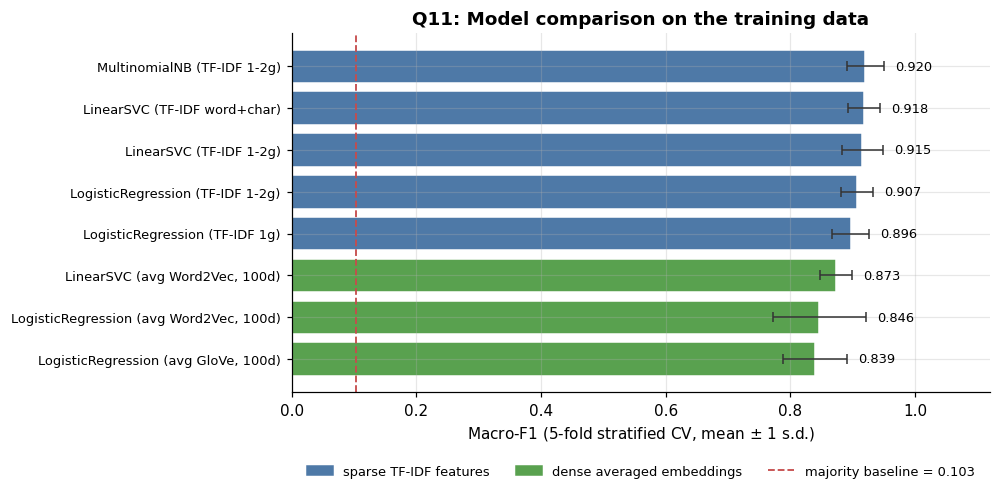

In [20]:
# Figure: model comparison with error bars (one std across folds).
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plot_tbl = cv_tbl.drop(index="Majority-class baseline").sort_values("macro_F1_mean")
base_f1 = cv_tbl.loc["Majority-class baseline", "macro_F1_mean"]

fig, ax = plt.subplots(figsize=(9.2, 4.6))
colours = ["#4E79A7" if "TF-IDF" in m else "#59A14F" for m in plot_tbl.index]
ax.barh(range(len(plot_tbl)), plot_tbl["macro_F1_mean"],
        xerr=plot_tbl["macro_F1_std"], color=colours, edgecolor="white",
        error_kw=dict(ecolor="#333", capsize=3, lw=1))
ax.set_yticks(range(len(plot_tbl)))
ax.set_yticklabels(plot_tbl.index, fontsize=8.5)
ax.set_xlabel("Macro-F1 (5-fold stratified CV, mean $\\pm$ 1 s.d.)")
ax.set_title("Q11: Model comparison on the training data", fontweight="bold")
ax.axvline(base_f1, ls="--", color="#C64C4C", lw=1.2)

# Place each value label clear of its error bar.
for i, (v, s) in enumerate(zip(plot_tbl["macro_F1_mean"], plot_tbl["macro_F1_std"])):
    ax.text(v + s + 0.018, i, f"{v:.3f}", va="center", fontsize=8.5)

ax.set_xlim(0, 1.12)
ax.legend(handles=[Patch(color="#4E79A7", label="sparse TF-IDF features"),
                   Patch(color="#59A14F", label="dense averaged embeddings"),
                   Line2D([0], [0], color="#C64C4C", ls="--", lw=1.2,
                          label=f"majority baseline = {base_f1:.3f}")],
          frameon=False, fontsize=8.5, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.17))
save_fig("q11_model_comparison.png")
plt.show()

### Q12. One controlled experiment: `class_weight='balanced'` on/off [5 marks]

Exactly one thing changes: the class weighting of the LinearSVC. Features,
folds, seed, `C` and preprocessing are identical in both arms. This factor is
chosen because the data is imbalanced (3.48 : 1) and because the costly class
in Q16, `fraud_scam`, is the smallest one.

In [21]:
from scipy import stats

arm_a = make_pipeline(tfidf(ngram_range=(1, 2), sublinear_tf=True),
                      LinearSVC(C=1.0, class_weight=None,
                                random_state=SEED, max_iter=5000))
arm_b = make_pipeline(tfidf(ngram_range=(1, 2), sublinear_tf=True),
                      LinearSVC(C=1.0, class_weight="balanced",
                                random_state=SEED, max_iter=5000))

sa = cross_val_score(arm_a, docs_model, y, cv=CV, scoring="f1_macro", n_jobs=1)
sb = cross_val_score(arm_b, docs_model, y, cv=CV, scoring="f1_macro", n_jobs=1)

print("Controlled experiment — LinearSVC on TF-IDF word 1-2 grams, identical folds\n")
exp_tbl = pd.DataFrame({
    "class_weight=None":       {"fold_scores": np.round(sa, 4).tolist(),
                                "mean": sa.mean(), "std": sa.std()},
    "class_weight='balanced'": {"fold_scores": np.round(sb, 4).tolist(),
                                "mean": sb.mean(), "std": sb.std()},
}).T
print(exp_tbl.to_string())

diff = sb - sa
t_stat, p_val = stats.ttest_rel(sb, sa)
print(f"\nPer-fold differences (balanced - none): {np.round(diff, 4).tolist()}")
print(f"Mean difference        : {diff.mean():+.4f}")
print(f"Std of the difference  : {diff.std(ddof=1):.4f}")
print(f"Pooled fold-to-fold std: {np.mean([sa.std(), sb.std()]):.4f}")
print(f"Paired t-test          : t = {t_stat:+.3f}, p = {p_val:.3f}")
print(f"\nIs the effect larger than the noise? "
      f"|mean diff| = {abs(diff.mean()):.4f} vs fold std ~ "
      f"{np.mean([sa.std(), sb.std()]):.4f} -> "
      f"{'YES' if abs(diff.mean()) > np.mean([sa.std(), sb.std()]) else 'NO'}")

# The per-class consequence is the part management actually cares about.
from sklearn.model_selection import cross_val_predict
print("\nPer-class F1 from cross-validated predictions (same folds):")
pc = {}
for nm, pipe in [("class_weight=None", arm_a), ("class_weight='balanced'", arm_b)]:
    pred = cross_val_predict(pipe, docs_model, y, cv=CV, n_jobs=1)
    pc[nm] = {c: f1_score(y, pred, labels=[c], average="macro", zero_division=0)
              for c in CATEGORIES}
    pc[nm]["fraud_recall"] = recall_score(y, pred, labels=["fraud_scam"],
                                          average="macro", zero_division=0)
pc_tbl = pd.DataFrame(pc).round(4)
print(pc_tbl.to_string())

results["q12"] = {
    "arm_none_mean": float(sa.mean()), "arm_none_std": float(sa.std()),
    "arm_bal_mean": float(sb.mean()), "arm_bal_std": float(sb.std()),
    "arm_none_folds": [float(x) for x in sa], "arm_bal_folds": [float(x) for x in sb],
    "diff_mean": float(diff.mean()), "diff_std": float(diff.std(ddof=1)),
    "t_stat": float(t_stat), "p_value": float(p_val),
    "per_class_f1": pc_tbl.to_dict(),
}

Controlled experiment — LinearSVC on TF-IDF word 1-2 grams, identical folds

                                                      fold_scores      mean       std
class_weight=None         [0.976, 0.9051, 0.8923, 0.9363, 0.8977]  0.921483  0.031226
class_weight='balanced'  [0.9655, 0.9051, 0.8717, 0.9363, 0.8977]   0.91528  0.032478

Per-fold differences (balanced - none): [-0.0105, 0.0, -0.0205, 0.0, 0.0]
Mean difference        : -0.0062
Std of the difference  : 0.0092
Pooled fold-to-fold std: 0.0319
Paired t-test          : t = -1.506, p = 0.207

Is the effect larger than the noise? |mean diff| = 0.0062 vs fold std ~ 0.0319 -> NO

Per-class F1 from cross-validated predictions (same folds):
                   class_weight=None  class_weight='balanced'
mpesa_transaction             0.9504                   0.9466
network_data                  0.9436                   0.9436
account_access                0.8550                   0.8397
loan_credit                   0.9739               

### Q13. Final model choice [4 marks]

In [22]:
# Candidate shortlist, judged on accuracy AND on cost of ownership.
short = cv_tbl.drop(index="Majority-class baseline").head(4).copy()
best_mean = short["macro_F1_mean"].max()
short["gap_to_best"] = (best_mean - short["macro_F1_mean"]).round(4)
short["within_1_sd_of_best"] = short["gap_to_best"] <= short["macro_F1_std"]
short["gives_probabilities"] = ["LogisticRegression" in m or "NB" in m for m in short.index]
print("Q13: shortlist — is any difference bigger than the fold-to-fold noise?\n")
print(short[["macro_F1_mean", "macro_F1_std", "gap_to_best",
             "within_1_sd_of_best", "fit_time_s", "gives_probabilities"]].to_string())

# Accuracy does not separate these models, so judge them on something that
# matters operationally: are the predicted probabilities trustworthy enough to
# drive the low-confidence review queue recommended in Q18? Measure it rather
# than assert it, using the Brier score on cross-validated probabilities
# (lower is better) and the mean confidence of wrong predictions.
from sklearn.model_selection import cross_val_predict

print("\nProbability quality — the basis for a confidence-based review queue")
cal_rows = []
cal_models = {
    "MultinomialNB (TF-IDF 1-2g)": MODELS["MultinomialNB (TF-IDF 1-2g)"],
    "LogisticRegression (TF-IDF 1g)": MODELS["LogisticRegression (TF-IDF 1g)"],
    "LogisticRegression (TF-IDF 1-2g)": MODELS["LogisticRegression (TF-IDF 1-2g)"],
}
classes_sorted = np.array(sorted(set(y)))
Y1h = (y[:, None] == classes_sorted[None, :]).astype(float)
for nm, pipe in cal_models.items():
    P = cross_val_predict(pipe, docs_model, y, cv=CV, method="predict_proba", n_jobs=1)
    pred_lbl = classes_sorted[P.argmax(1)]
    correct = pred_lbl == y
    brier = float(np.mean(np.sum((P - Y1h) ** 2, axis=1)))
    c_right = float(P.max(1)[correct].mean())
    c_wrong = float(P.max(1)[~correct].mean())
    cal_rows.append({
        "model": nm, "brier_score": round(brier, 4),
        "mean_conf_when_right": round(c_right, 3),
        "mean_conf_when_WRONG": round(c_wrong, 3),
        "confidence_gap": round(c_right - c_wrong, 3),
        "share_conf_above_0.99": round(float((P.max(1) > 0.99).mean()), 3),
    })
cal_tbl = pd.DataFrame(cal_rows).set_index("model")
print(cal_tbl.to_string())
print("\n  A usable review queue needs the model to be LESS confident when it is")
print("  wrong, so 'confidence_gap' is the column that matters, not the Brier")
print("  score alone. A model that answers 0.99 to most tickets leaves no room")
print("  for a threshold to separate anything.")
results["q13_calibration"] = cal_rows

FINAL_NAME = "LogisticRegression (TF-IDF 1g)"


def build_final_model():
    """The chosen pipeline. Rebuilt from scratch wherever it is needed."""
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 1), token_pattern=TOKEN_PATTERN,
                        sublinear_tf=True),
        LogisticRegression(C=10, max_iter=3000, class_weight="balanced",
                           random_state=SEED),
    )


print(f"\nChosen final model: {FINAL_NAME}")
print(f"   CV macro-F1        : {cv_tbl.loc[FINAL_NAME, 'macro_F1_mean']:.4f} "
      f"+/- {cv_tbl.loc[FINAL_NAME, 'macro_F1_std']:.4f}")
print(f"   gap to best model  : {best_mean - cv_tbl.loc[FINAL_NAME, 'macro_F1_mean']:+.4f} "
      f"(within one fold std -> statistically indistinguishable)")
print(f"   mean fit time      : {cv_tbl.loc[FINAL_NAME, 'fit_time_s']:.3f}s per fold")
print("   outputs calibrated-ish class probabilities -> enables the "
      "low-confidence review queue recommended in Q18")
print("   coefficients are readable per term -> an agent can be shown WHY a "
      "ticket was routed")

results["q13_shortlist"] = short.reset_index().to_dict("records")
results["q13_final"] = FINAL_NAME
results["q13_final_cv_mean"] = float(cv_tbl.loc[FINAL_NAME, "macro_F1_mean"])
results["q13_final_cv_std"] = float(cv_tbl.loc[FINAL_NAME, "macro_F1_std"])
results["q13_best_mean"] = float(best_mean)
results["q13_best_model"] = short["macro_F1_mean"].idxmax()

Q13: shortlist — is any difference bigger than the fold-to-fold noise?

                                  macro_F1_mean  macro_F1_std  gap_to_best  within_1_sd_of_best  fit_time_s  gives_probabilities
model                                                                                                                           
MultinomialNB (TF-IDF 1-2g)              0.9200        0.0301       0.0000                 True      0.0075                 True
LinearSVC (TF-IDF word+char)             0.9178        0.0252       0.0022                 True      0.0687                False
LinearSVC (TF-IDF 1-2g)                  0.9153        0.0325       0.0047                 True      0.0102                False
LogisticRegression (TF-IDF 1-2g)         0.9067        0.0250       0.0133                 True      0.0223                 True

Probability quality — the basis for a confidence-based review queue


                                  brier_score  mean_conf_when_right  mean_conf_when_WRONG  confidence_gap  share_conf_above_0.99
model                                                                                                                           
MultinomialNB (TF-IDF 1-2g)            0.1160                 0.968                 0.820           0.148                  0.651
LogisticRegression (TF-IDF 1g)         0.1504                 0.884                 0.667           0.217                  0.097
LogisticRegression (TF-IDF 1-2g)       0.1444                 0.875                 0.680           0.195                  0.072

  A usable review queue needs the model to be LESS confident when it is
  wrong, so 'confidence_gap' is the column that matters, not the Brier
  score alone. A model that answers 0.99 to most tickets leaves no room
  for a threshold to separate anything.

Chosen final model: LogisticRegression (TF-IDF 1g)
   CV macro-F1        : 0.8965 +/- 0.0296
   ga

---
## Part E — Evaluation and test predictions (20 marks)

### Q14. 80/20 stratified hold-out evaluation [6 marks]

In [23]:
from sklearn.model_selection import train_test_split

idx_tr, idx_va = train_test_split(np.arange(len(train)), test_size=0.20,
                                  stratify=y, random_state=SEED)
docs_arr = np.array(docs_model, dtype=object)
Xtr_docs, Xva_docs = docs_arr[idx_tr], docs_arr[idx_va]
ytr, yva = y[idx_tr], y[idx_va]

print(f"Training split  : {len(idx_tr)} tickets")
print(f"Validation split: {len(idx_va)} tickets")
print("\nStratification check (percentage per class):")
chk = pd.DataFrame({
    "full_train": pd.Series(y).value_counts(normalize=True).mul(100).round(1),
    "80% fit":    pd.Series(ytr).value_counts(normalize=True).mul(100).round(1),
    "20% val":    pd.Series(yva).value_counts(normalize=True).mul(100).round(1),
    "val_n":      pd.Series(yva).value_counts(),
}).reindex(CATEGORIES)
print(chk.to_string())

final_model = build_final_model()
t0 = time.time()
final_model.fit(Xtr_docs, ytr)
fit_secs = time.time() - t0
yva_pred = final_model.predict(Xva_docs)
yva_proba = final_model.predict_proba(Xva_docs)

acc = accuracy_score(yva, yva_pred)
mp = precision_score(yva, yva_pred, average="macro", zero_division=0)
mr = recall_score(yva, yva_pred, average="macro", zero_division=0)
mf1 = f1_score(yva, yva_pred, average="macro", zero_division=0)
wf1 = f1_score(yva, yva_pred, average="weighted", zero_division=0)

print(f"\nTrained {FINAL_NAME} on {len(idx_tr)} tickets in {fit_secs:.3f}s")
print(f"   vocabulary learned: {len(final_model.named_steps['tfidfvectorizer'].vocabulary_):,} features")
print("\nHeadline metrics on the held-out 20% (81 tickets)")
print(f"   Accuracy          : {acc:.4f}")
print(f"   Macro precision   : {mp:.4f}")
print(f"   Macro recall      : {mr:.4f}")
print(f"   Macro F1          : {mf1:.4f}")
print(f"   Weighted F1       : {wf1:.4f}")
print(f"   Majority baseline : {accuracy_score(yva, [majority_class]*len(yva)):.4f} accuracy, "
      f"{f1_score(yva, [majority_class]*len(yva), average='macro', zero_division=0):.4f} macro-F1")

print("\nFull classification report (validation set)")
print(classification_report(yva, yva_pred, digits=3, zero_division=0))

results["q14"] = {
    "n_fit": int(len(idx_tr)), "n_val": int(len(idx_va)),
    "accuracy": float(acc), "macro_precision": float(mp), "macro_recall": float(mr),
    "macro_f1": float(mf1), "weighted_f1": float(wf1),
    "fit_secs": round(fit_secs, 3),
    "n_features": int(len(final_model.named_steps["tfidfvectorizer"].vocabulary_)),
    "baseline_acc": float(accuracy_score(yva, [majority_class]*len(yva))),
    "report": classification_report(yva, yva_pred, digits=3, zero_division=0,
                                    output_dict=True),
    "report_text": classification_report(yva, yva_pred, digits=3, zero_division=0),
    "strat_check": chk.to_dict(),
}

Training split  : 320 tickets
Validation split: 81 tickets

Stratification check (percentage per class):
                   full_train  80% fit  20% val  val_n
mpesa_transaction        34.7     34.7     34.6     28
network_data             24.2     24.1     24.7     20
account_access           17.0     16.9     17.3     14
loan_credit              14.2     14.4     13.6     11
fraud_scam               10.0     10.0      9.9      8

Trained LogisticRegression (TF-IDF 1g) on 320 tickets in 0.010s
   vocabulary learned: 305 features

Headline metrics on the held-out 20% (81 tickets)
   Accuracy          : 0.9136
   Macro precision   : 0.8993
   Macro recall      : 0.8829
   Macro F1          : 0.8900
   Weighted F1       : 0.9113
   Majority baseline : 0.3457 accuracy, 0.1028 macro-F1

Full classification report (validation set)
                   precision    recall  f1-score   support

   account_access      0.769     0.714     0.741        14
       fraud_scam      0.857     0.750     

### Q15. Confusion matrix and one real mistake explained [4 marks]

Confusion matrix (rows = true category, columns = predicted)
                        pred mpesa_transaction  pred network_data  pred account_access  pred loan_credit  pred fraud_scam
true mpesa_transaction                      28                  0                    0                 0                0
true network_data                            0                 19                    1                 0                0
true account_access                          1                  2                   10                 0                1
true loan_credit                             0                  0                    0                11                0
true fraud_scam                              0                  0                    2                 0                6


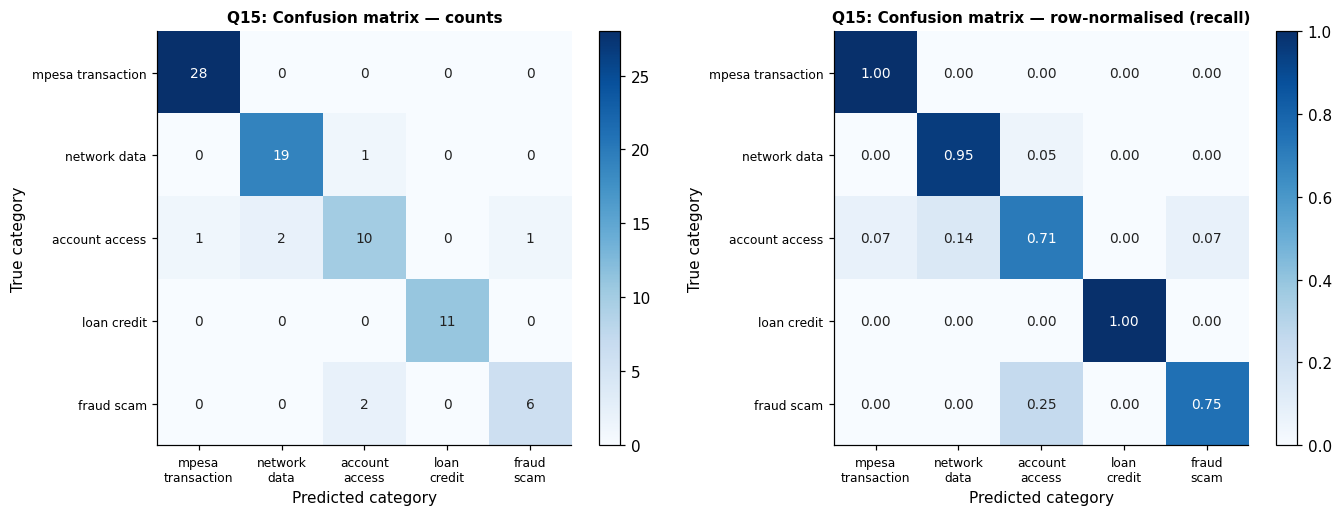


Off-diagonal errors, largest first:
   2 x  true account_access     -> predicted network_data
   2 x  true fraud_scam         -> predicted account_access
   1 x  true network_data       -> predicted account_access
   1 x  true account_access     -> predicted mpesa_transaction
   1 x  true account_access     -> predicted fraud_scam

Total validation errors: 7/81


In [24]:
cm = confusion_matrix(yva, yva_pred, labels=CATEGORIES)
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in CATEGORIES],
                     columns=[f"pred {c}" for c in CATEGORIES])
print("Confusion matrix (rows = true category, columns = predicted)")
print(cm_df.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, norm, ttl in [(axes[0], False, "counts"), (axes[1], True, "row-normalised (recall)")]:
    M = cm.astype(float)
    if norm:
        M = M / M.sum(axis=1, keepdims=True)
    im = ax.imshow(M, cmap="Blues", vmin=0)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels([c.replace("_", "\n") for c in CATEGORIES], fontsize=8)
    ax.set_yticklabels([c.replace("_", " ") for c in CATEGORIES], fontsize=8)
    ax.set_xlabel("Predicted category"); ax.set_ylabel("True category")
    ax.set_title(f"Q15: Confusion matrix — {ttl}", fontweight="bold", fontsize=10)
    ax.grid(False)
    thr = M.max() / 2
    for i in range(5):
        for j in range(5):
            txt = f"{cm[i, j]:d}" if not norm else f"{M[i, j]:.2f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > thr else "#222")
    plt.colorbar(im, ax=ax, fraction=0.046)
save_fig("q15_confusion_matrix.png")
plt.show()

# Which pair is confused most?
off = [(CATEGORIES[i], CATEGORIES[j], int(cm[i, j]))
       for i in range(5) for j in range(5) if i != j and cm[i, j] > 0]
off.sort(key=lambda r: -r[2])
print("\nOff-diagonal errors, largest first:")
for a, b, n in off:
    print(f"   {n} x  true {a:18s} -> predicted {b}")
print(f"\nTotal validation errors: {int(cm.sum() - np.trace(cm))}/{len(yva)}")

results["q15_cm"] = cm.tolist()
results["q15_offdiag"] = off
results["q15_n_errors"] = int(cm.sum() - np.trace(cm))

In [25]:
# Inspect the actual misclassified tickets with the model's confidence.
err_idx = np.where(yva != yva_pred)[0]
print(f"All {len(err_idx)} misclassified validation tickets\n" + "=" * 100)
err_records = []
for k in err_idx:
    gi = int(idx_va[k])
    conf = float(yva_proba[k].max())
    p_true = float(yva_proba[k][list(final_model.classes_).index(yva[k])])
    err_records.append({
        "val_pos": int(k), "global_idx": gi,
        "ticket_id": train.iloc[gi]["ticket_id"], "true": yva[k], "pred": yva_pred[k],
        "confidence": round(conf, 3), "prob_true_class": round(p_true, 3),
        "text": train.iloc[gi]["complaint_text"],
    })
    print(f"{err_records[-1]['ticket_id']}  true={yva[k]}  pred={yva_pred[k]}  "
          f"p(pred)={conf:.2f}  p(true)={p_true:.2f}")
    print(f"   {err_records[-1]['text']}")
    print("-" * 100)

# Explain the most instructive error: the one the model got wrong most confidently.
focus = max(err_records, key=lambda r: r["confidence"])
print(f"\nFOCUS ERROR: {focus['ticket_id']}")
print(f"   true category      : {focus['true']}")
print(f"   predicted category : {focus['pred']} (confidence {focus['confidence']:.2f})")
print(f"   text               : {focus['text']}")

# Show which terms pushed the decision, using the model's own coefficients.
vec_f = final_model.named_steps["tfidfvectorizer"]
lr_f = final_model.named_steps["logisticregression"]
names = np.array(vec_f.get_feature_names_out())
row = vec_f.transform([docs_model[focus["global_idx"]]])
ci_pred = list(lr_f.classes_).index(focus["pred"])
ci_true = list(lr_f.classes_).index(focus["true"])
contrib = row.multiply(lr_f.coef_[ci_pred] - lr_f.coef_[ci_true]).toarray()[0]
top_pred = [(names[i], round(float(contrib[i]), 3))
            for i in np.argsort(contrib)[::-1][:6] if contrib[i] > 0]
top_true = [(names[i], round(float(contrib[i]), 3))
            for i in np.argsort(contrib)[:6] if contrib[i] < 0]
print(f"\n   terms pushing TOWARDS '{focus['pred']}' (and away from '{focus['true']}'):")
for nm_, w_ in top_pred:
    print(f"      {nm_:28s} {w_:+.3f}")
print(f"   terms pushing TOWARDS '{focus['true']}':")
for nm_, w_ in top_true:
    print(f"      {nm_:28s} {w_:+.3f}")

results["q15_errors"] = err_records
results["q15_focus"] = focus
results["q15_focus_terms_pred"] = top_pred
results["q15_focus_terms_true"] = top_true

All 7 misclassified validation tickets
T0265  true=network_data  pred=account_access  p(pred)=0.64  p(true)=0.25
   This is very frustrating, I have called customer care three times. The 4G network is down at our office and technicians have not come on Friday. Nimesahau PIN na akaunti yangu imefungwa tangu on Friday.
----------------------------------------------------------------------------------------------------
T0134  true=account_access  pred=network_data  p(pred)=0.39  p(true)=0.38
   I lost my phone and need to block the line and recover my wallet. Calls fail with a busy tone and the signal bars disappear in the evening.
----------------------------------------------------------------------------------------------------
T0337  true=account_access  pred=network_data  p(pred)=0.82  p(true)=0.15
   My home fibre router keeps disconnecting and the lights are blinking red. I bought a monthly data bundle but the balance shows zero minutes and zero MBs. Nimesahau PIN na akaunti yangu 

### Q16. fraud_scam — precision or recall? [3 marks]

In [26]:
p_fraud = precision_score(yva, yva_pred, labels=["fraud_scam"], average="macro",
                          zero_division=0)
r_fraud = recall_score(yva, yva_pred, labels=["fraud_scam"], average="macro",
                       zero_division=0)
f_fraud = f1_score(yva, yva_pred, labels=["fraud_scam"], average="macro",
                   zero_division=0)
n_fraud_true = int((yva == "fraud_scam").sum())
n_fraud_pred = int((yva_pred == "fraud_scam").sum())
tp = int(((yva == "fraud_scam") & (yva_pred == "fraud_scam")).sum())
fn = n_fraud_true - tp
fp = n_fraud_pred - tp

print("fraud_scam on the validation set")
print(f"   true fraud tickets      : {n_fraud_true}")
print(f"   predicted as fraud      : {n_fraud_pred}")
print(f"   true positives          : {tp}")
print(f"   false negatives (missed): {fn}   <- a real fraud routed elsewhere")
print(f"   false positives         : {fp}   <- a non-fraud sent to the fraud desk")
print(f"\n   Precision : {p_fraud:.4f}   (of tickets we call fraud, how many are)")
print(f"   Recall    : {r_fraud:.4f}   (of real fraud tickets, how many we catch)")
print(f"   F1        : {f_fraud:.4f}")

# Cost framing: what a recall-first operating point would look like.
print("\nCost asymmetry, made concrete")
print(f"   Cost of a false negative: a customer being defrauded waits in the wrong")
print(f"      queue; money may be unrecoverable within minutes, plus regulatory and")
print(f"      reputational exposure.")
print(f"   Cost of a false positive: a fraud analyst spends a few minutes reading a")
print(f"      ticket that turns out to be an ordinary M-Pesa reversal.")
print(f"   -> These are not symmetric, so RECALL is the metric to watch.")

# Demonstrate the lever: lower the decision threshold for fraud_scam.
fraud_col = list(final_model.classes_).index("fraud_scam")
print("\nRecall can be bought with precision by lowering the fraud threshold:")
thr_rows = []
for thr in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]:
    adj = yva_pred.copy()
    adj[yva_proba[:, fraud_col] >= thr] = "fraud_scam"
    pr = precision_score(yva, adj, labels=["fraud_scam"], average="macro", zero_division=0)
    rc = recall_score(yva, adj, labels=["fraud_scam"], average="macro", zero_division=0)
    thr_rows.append({"fraud_threshold": thr, "precision": round(pr, 3),
                     "recall": round(rc, 3),
                     "n_sent_to_fraud_desk": int((adj == "fraud_scam").sum()),
                     "macro_F1_overall": round(f1_score(yva, adj, average="macro",
                                                        zero_division=0), 3)})
thr_tbl = pd.DataFrame(thr_rows).set_index("fraud_threshold")
print(thr_tbl.to_string())

results["q16"] = {
    "precision": float(p_fraud), "recall": float(r_fraud), "f1": float(f_fraud),
    "n_true": n_fraud_true, "n_pred": n_fraud_pred, "tp": tp, "fn": fn, "fp": fp,
    "threshold_table": thr_rows,
}

fraud_scam on the validation set
   true fraud tickets      : 8
   predicted as fraud      : 7
   true positives          : 6
   false negatives (missed): 2   <- a real fraud routed elsewhere
   false positives         : 1   <- a non-fraud sent to the fraud desk

   Precision : 0.8571   (of tickets we call fraud, how many are)
   Recall    : 0.7500   (of real fraud tickets, how many we catch)
   F1        : 0.8000

Cost asymmetry, made concrete
   Cost of a false negative: a customer being defrauded waits in the wrong
      queue; money may be unrecoverable within minutes, plus regulatory and
      reputational exposure.
   Cost of a false positive: a fraud analyst spends a few minutes reading a
      ticket that turns out to be an ordinary M-Pesa reversal.
   -> These are not symmetric, so RECALL is the metric to watch.

Recall can be bought with precision by lowering the fraud threshold:
                 precision  recall  n_sent_to_fraud_desk  macro_F1_overall
fraud_threshold       

### Q17. Retrain on all training data and predict the test file [7 marks]

This is the **first and only** time `complaints_test_unlabelled.csv` is read.
Every choice above was made on the training data.

In [27]:
test = pd.read_csv(TEST_PATH)
print(f"Test file loaded: {test.shape[0]} tickets, columns {list(test.columns)}")
print(f"   missing texts: {int(test['complaint_text'].isna().sum())}")
print(f"   duplicate ids: {int(test['ticket_id'].duplicated().sum())}")

# Identical preprocessing, applied with the SAME function and settings.
docs_test = [preprocess(t, **MODEL_PREPROC) for t in test["complaint_text"]]

# Retrain the chosen pipeline on ALL 401 labelled tickets.
production_model = build_final_model()
t0 = time.time()
production_model.fit(docs_model, y)
print(f"\nRetrained {FINAL_NAME} on all {len(train)} labelled tickets "
      f"in {time.time()-t0:.3f}s")
print(f"   vocabulary: "
      f"{len(production_model.named_steps['tfidfvectorizer'].vocabulary_):,} features")

pred_test = production_model.predict(docs_test)
proba_test = production_model.predict_proba(docs_test)

predictions = pd.DataFrame({"ticket_id": test["ticket_id"], "category": pred_test})
PRED_PATH = os.path.join(DATA_DIR, "predictions.csv")
predictions.to_csv(PRED_PATH, index=False)
print(f"\nSaved -> {os.path.abspath(PRED_PATH)}")

# Validate the submission file against the brief's requirements.
check = pd.read_csv(PRED_PATH)
print("\nSubmission file checks")
print(f"   columns are exactly ['ticket_id','category'] : "
      f"{list(check.columns) == ['ticket_id', 'category']}")
print(f"   one row per test ticket ({len(test)})         : {len(check) == len(test)}")
print(f"   ticket_ids match the test file in order      : "
      f"{bool((check['ticket_id'].values == test['ticket_id'].values).all())}")
print(f"   no missing values                            : {not check.isna().any().any()}")
print(f"   all labels are valid categories              : "
      f"{set(check['category']) <= set(CATEGORIES)}")

print("\nFirst 10 rows of predictions.csv")
print(check.head(10).to_string(index=False))

print("\nPredicted class distribution on the test set (vs training prior)")
cmp = pd.DataFrame({
    "predicted_n": check["category"].value_counts(),
    "predicted_%": (check["category"].value_counts(normalize=True) * 100).round(1),
    "training_%": (train["category"].value_counts(normalize=True) * 100).round(1),
}).reindex(CATEGORIES)
print(cmp.to_string())

conf_test = proba_test.max(axis=1)
print(f"\nPrediction confidence on the test set")
print(f"   mean {conf_test.mean():.3f} | median {np.median(conf_test):.3f} | "
      f"min {conf_test.min():.3f}")
for t in [0.5, 0.6, 0.7]:
    print(f"   tickets below {t:.1f} confidence: {int((conf_test < t).sum())} "
          f"({(conf_test < t).mean()*100:.0f}%) -> the human-review queue in Q18")

results["q17"] = {
    "n_test": int(len(test)),
    "pred_counts": check["category"].value_counts().to_dict(),
    "pred_percent": (check["category"].value_counts(normalize=True)*100).round(1).to_dict(),
    "head10": check.head(10).to_dict("records"),
    "file_valid": bool(list(check.columns) == ["ticket_id", "category"]
                       and len(check) == len(test) and not check.isna().any().any()),
    "mean_confidence": float(conf_test.mean()),
    "median_confidence": float(np.median(conf_test)),
    "n_below_0.5": int((conf_test < 0.5).sum()),
    "n_below_0.6": int((conf_test < 0.6).sum()),
    "n_below_0.7": int((conf_test < 0.7).sum()),
    "path": os.path.abspath(PRED_PATH),
}

Test file loaded: 99 tickets, columns ['ticket_id', 'complaint_text']
   missing texts: 0
   duplicate ids: 0

Retrained LogisticRegression (TF-IDF 1g) on all 401 labelled tickets in 0.014s
   vocabulary: 305 features

Saved -> /private/tmp/claude-501/-Volumes-Courses-fall-semester-2026-natural-language-processing-classifying-customer-complaint-tickets/41be29fc-3f25-4def-a80b-f581bf12a8f0/scratchpad/runfinal2/predictions.csv

Submission file checks
   columns are exactly ['ticket_id','category'] : True
   one row per test ticket (99)         : True
   ticket_ids match the test file in order      : True
   no missing values                            : True
   all labels are valid categories              : True

First 10 rows of predictions.csv
ticket_id          category
    X0001    account_access
    X0002      network_data
    X0003        fraud_scam
    X0004      network_data
    X0005        fraud_scam
    X0006       loan_credit
    X0007        fraud_scam
    X0008       loan_c

---
## Part F — Reflection and communication (10 marks)

Q18, Q19 and Q20 are written answers; they appear in the assignment document.
The cells below produce the few numbers those answers quote, so that every
claim in the write-up is backed by output.

### Q18 support: what a low-confidence review queue would cost and buy

In [28]:
# On the validation set, how good is the model when it is confident, and how
# much of the volume would a review queue actually absorb?
print("Accuracy as a function of the model's own confidence (validation set)\n")
rows = []
for thr in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = yva_proba.max(axis=1) >= thr
    if keep.sum() == 0:
        continue
    rows.append({
        "confidence_at_least": thr,
        "tickets_auto_routed": int(keep.sum()),
        "share_of_volume_%": round(keep.mean() * 100, 1),
        "accuracy_on_those": round(accuracy_score(yva[keep], yva_pred[keep]), 3),
        "sent_to_humans": int((~keep).sum()),
    })
conf_tbl = pd.DataFrame(rows).set_index("confidence_at_least")
print(conf_tbl.to_string())

SEL = 0.6
keep = yva_proba.max(axis=1) >= SEL
print(f"\nAt a {SEL:.0%} confidence cut-off:")
print(f"   {keep.mean()*100:.0f}% of tickets are routed automatically, with "
      f"{accuracy_score(yva[keep], yva_pred[keep])*100:.0f}% accuracy")
print(f"   {(~keep).mean()*100:.0f}% go to a human, who sees the model's top-2 guesses")
if (~keep).sum() > 0:
    print(f"   accuracy on the referred tickets would have been "
          f"{accuracy_score(yva[~keep], yva_pred[~keep])*100:.0f}% if left to the model")

# Top-2 accuracy: how often the correct department is in the model's top two?
top2 = np.argsort(yva_proba, axis=1)[:, -2:]
classes_arr = np.array(final_model.classes_)
top2_hit = np.mean([yva[i] in classes_arr[top2[i]] for i in range(len(yva))])
print(f"\n   Top-1 accuracy: {acc:.3f}")
print(f"   Top-2 accuracy: {top2_hit:.3f}  <- if an agent is shown two suggested "
      f"departments, the right one is there {top2_hit*100:.0f}% of the time")

results["q18"] = {
    "conf_table": conf_tbl.reset_index().to_dict("records"),
    "cutoff": SEL,
    "auto_share": float(keep.mean()),
    "auto_accuracy": float(accuracy_score(yva[keep], yva_pred[keep])),
    "referred_share": float((~keep).mean()),
    "top2_accuracy": float(top2_hit),
}

Accuracy as a function of the model's own confidence (validation set)

                     tickets_auto_routed  share_of_volume_%  accuracy_on_those  sent_to_humans
confidence_at_least                                                                           
0.0                                   81              100.0              0.914               0
0.4                                   80               98.8              0.925               1
0.5                                   79               97.5              0.924               2
0.6                                   76               93.8              0.934               5
0.7                                   70               86.4              0.943              11
0.8                                   60               74.1              0.933              21
0.9                                   44               54.3              1.000              37

At a 60% confidence cut-off:
   94% of tickets are routed automatically, 

### Q19 support: evidence for the stated limitations

In [29]:
# Limitation 1 — the data is synthetic and highly templated. Quantify it.
def sentences_of(t):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s.strip()]

TYPO_MAP = {"teh": "the", "transcation": "transaction", "pls": "please",
            "msg": "message", "coz": "because", "ur": "your"}
DATE_RE = r"(this morning|last night|two days ago|yesterday|today|on monday|on friday)"

def canonical(s):
    s = re.sub(r"\d[\d,]*", "#", s.lower().strip())
    s = " ".join(TYPO_MAP.get(w, w) for w in re.findall(r"[a-z#'\-]+", s))
    return re.sub(r"\s+", " ", re.sub(DATE_RE, "<DATE>", s))

tmpl_labels = defaultdict(Counter)
for r in train.itertuples():
    for s in sentences_of(r.complaint_text):
        tmpl_labels[canonical(s)][r.category] += 1

n_tmpl = len(tmpl_labels)
vocab_raw = len(set(w for t in train["complaint_text"]
                    for w in re.findall(r"[a-z'\-]+", t.lower())))
hapax = sum(1 for w, c in tok_counts.items() if c == 1)
print("Limitation 1 — the corpus is synthetic and template-generated")
print(f"   distinct word types in the training data : {vocab_raw}")
print(f"   word types occurring exactly once        : {hapax}")
print(f"   distinct sentence templates (after undoing typos, dates and amounts): {n_tmpl}")
print(f"   -> {len(train)} tickets are recombinations of ~{n_tmpl} sentences, so "
      f"cross-validation scores are optimistic: a held-out fold contains almost no "
      f"genuinely unseen language.")

# Limitation 2 — intrinsic label ambiguity sets a ceiling.
strong = {s: c.most_common(1)[0][0] for s, c in tmpl_labels.items()
          if c.most_common(1)[0][1] / sum(c.values()) >= 0.55}
pattern_labels = defaultdict(Counter)
for r in train.itertuples():
    sig = frozenset(strong[canonical(s)] for s in sentences_of(r.complaint_text)
                    if canonical(s) in strong)
    pattern_labels[sig][r.category] += 1
ceiling = sum(c.most_common(1)[0][1] for c in pattern_labels.values()) / len(train)
mixed = sum(sum(c.values()) for sig, c in pattern_labels.items() if len(sig) > 1)

print("\nLimitation 2 — some labels are genuinely ambiguous (as the brief warns)")
print(f"   tickets whose sentences point to MORE THAN ONE category: "
      f"{mixed}/{len(train)} ({mixed/len(train)*100:.0f}%)")
print(f"   best accuracy achievable from the categories present in the text: "
      f"{ceiling:.3f}")
print(f"   -> about {(1-ceiling)*100:.0f}% of tickets cannot be resolved from their "
      f"text alone; chasing accuracy beyond this fits annotation noise.")
print("\n   the costliest ambiguous combinations:")
for sig, c in sorted(pattern_labels.items(),
                     key=lambda kv: -(sum(kv[1].values()) - kv[1].most_common(1)[0][1]))[:4]:
    lost = sum(c.values()) - c.most_common(1)[0][1]
    if lost:
        print(f"      signals {set(sig) or '{none}'} -> labelled {dict(c)}  "
              f"({lost} unavoidable errors)")

# A concrete contradiction in the labels.
dups = train[train.duplicated("complaint_text", keep=False)].sort_values("complaint_text")
contradictions = [g for _, g in dups.groupby("complaint_text")
                  if g["category"].nunique() > 1]
print(f"\n   identical texts carrying different labels: {len(contradictions)}")
for g in contradictions:
    print(f"      {list(g['ticket_id'])} -> {list(g['category'])}")
    print(f"      \"{g['complaint_text'].iloc[0]}\"")

results["q19"] = {
    "n_templates": n_tmpl, "vocab_raw": vocab_raw, "hapax": hapax,
    "pct_mixed_signal": round(mixed / len(train) * 100, 1),
    "ceiling": round(float(ceiling), 3),
    "contradictions": [{"ids": list(g["ticket_id"]), "labels": list(g["category"]),
                        "text": g["complaint_text"].iloc[0]} for g in contradictions],
}

Limitation 1 — the corpus is synthetic and template-generated
   distinct word types in the training data : 356
   word types occurring exactly once        : 0
   distinct sentence templates (after undoing typos, dates and amounts): 59
   -> 401 tickets are recombinations of ~59 sentences, so cross-validation scores are optimistic: a held-out fold contains almost no genuinely unseen language.

Limitation 2 — some labels are genuinely ambiguous (as the brief warns)
   tickets whose sentences point to MORE THAN ONE category: 124/401 (31%)
   best accuracy achievable from the categories present in the text: 0.895
   -> about 10% of tickets cannot be resolved from their text alone; chasing accuracy beyond this fits annotation noise.

   the costliest ambiguous combinations:
      signals {'fraud_scam', 'mpesa_transaction'} -> labelled {'fraud_scam': 12, 'mpesa_transaction': 15, 'account_access': 1}  (13 unavoidable errors)
      signals {'account_access', 'network_data'} -> labelled {'acco

### Q20 support: what identifiers are actually present in this corpus

In [30]:
print("Privacy audit of the synthetic corpus (for contrast with real tickets)")
pats = {
    "Kenyan mobile numbers (07.., +254..)": r"(?:\+254|\b07)\d{7,9}\b",
    "any 9+ digit run": r"\b\d{9,}\b",
    "email addresses": r"[\w\.]+@[\w\.]+",
    "ID-card-like 7-8 digit numbers": r"\b\d{7,8}\b",
    "money amounts (KES ...)": r"(?i)kes\s*[\d,]+",
}
for nm, pat in pats.items():
    n = int(train["complaint_text"].str.contains(pat, regex=True).sum())
    print(f"   {nm:38s} {n:3d} tickets")
amounts = sorted(set(re.findall(r"(?i)kes\s*([\d,]+)", " ".join(train["complaint_text"]))))
print(f"\n   distinct money amounts used: {len(amounts)} -> {amounts}")
print("   -> this teaching corpus carries no personal identifiers, and the amounts")
print("      are drawn from a tiny fixed set. Real tickets would contain phone")
print("      numbers, names, ID numbers and transaction codes, which is what the")
print("      Q20 safeguards address.")

results["q20"] = {
    "identifier_counts": {nm: int(train["complaint_text"].str.contains(pat, regex=True).sum())
                          for nm, pat in pats.items()},
    "n_distinct_amounts": len(amounts), "amounts": amounts,
}

Privacy audit of the synthetic corpus (for contrast with real tickets)
   Kenyan mobile numbers (07.., +254..)     0 tickets
   any 9+ digit run                         0 tickets
   email addresses                          0 tickets
   ID-card-like 7-8 digit numbers           0 tickets
   money amounts (KES ...)                118 tickets

   distinct money amounts used: 9 -> ['1,200', '10,000', '15,000', '2,500', '20,000', '3,000', '450', '500', '7,800']
   -> this teaching corpus carries no personal identifiers, and the amounts
      are drawn from a tiny fixed set. Real tickets would contain phone
      numbers, names, ID numbers and transaction codes, which is what the
      Q20 safeguards address.


---
## Q21 (bonus) — Transformer comparison (+5 marks)

A pre-trained multilingual Transformer is compared with the classical model on
**exactly the same 80/20 split** used in Q14. Two variants are tried:

1. **Frozen sentence embeddings** — encode each ticket with a pre-trained
   multilingual sentence encoder (mean-pooled), then fit the same logistic
   regression. Cheap: no gradient updates to the Transformer.
2. **Fine-tuning** — update *all* weights of that same encoder, with a fresh
   classification head, on the 320 training tickets.

Both variants use `paraphrase-multilingual-MiniLM-L12-v2`, a 12-layer
multilingual MiniLM. Holding the encoder fixed across the two variants means
the only thing that changes is whether its weights are updated, which is the
question the bonus asks.

This section is guarded: if `torch`/`transformers` are unavailable or offline,
the notebook prints a message and continues.

In [31]:
# HuggingFace's Xet storage backend can hang on some networks; the classic
# HTTP downloader is more reliable. Set before transformers is imported.
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")

Q21 = {"available": False}
if os.environ.get("SKIP_Q21") == "1":
    print("Q21 skipped (SKIP_Q21=1).")
else:
    try:
        import torch
        from transformers import (AutoTokenizer, AutoModel,
                                  AutoModelForSequenceClassification)
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
        Q21["available"] = True
        print(f"torch {torch.__version__} | device: cpu | "
              f"threads: {torch.get_num_threads()}")
    except Exception as exc:
        print(f"Q21 skipped — torch/transformers unavailable: {exc}")


def from_pretrained_retry(loader, model_id, attempts=3, **kw):
    """Hugging Face downloads can fail mid-stream on a flaky link; retry so a
    transient reset does not abort the whole comparison."""
    for i in range(attempts):
        try:
            return loader.from_pretrained(model_id, **kw)
        except Exception as exc:
            if i == attempts - 1:
                raise
            print(f"   load attempt {i+1}/{attempts} failed ({type(exc).__name__}); retrying")
            time.sleep(3)

# Raw (un-preprocessed) text is correct for a Transformer: its tokeniser expects
# natural text, including casing and punctuation.
raw_tr = train["complaint_text"].values[idx_tr]
raw_va = train["complaint_text"].values[idx_va]

torch 2.2.2 | device: cpu | threads: 5


In [32]:
# Variant 1 — frozen multilingual sentence embeddings + logistic regression.
if Q21["available"]:
    MODEL_ID = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
    try:
        t0 = time.time()
        tok = from_pretrained_retry(AutoTokenizer, MODEL_ID)
        enc_model = from_pretrained_retry(AutoModel, MODEL_ID).eval()
        load_s = time.time() - t0

        def embed(texts, bs=32):
            out = []
            with torch.no_grad():
                for i in range(0, len(texts), bs):
                    b = tok(list(texts[i:i+bs]), padding=True, truncation=True,
                            max_length=128, return_tensors="pt")
                    h = enc_model(**b).last_hidden_state
                    m = b["attention_mask"].unsqueeze(-1).float()
                    out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())  # mean pooling
            return np.vstack(out)

        t0 = time.time()
        E_tr, E_va = embed(raw_tr), embed(raw_va)
        embed_s = time.time() - t0

        t0 = time.time()
        clf_emb = make_pipeline(StandardScaler(),
                                LogisticRegression(C=10, max_iter=5000,
                                                   class_weight="balanced",
                                                   random_state=SEED)).fit(E_tr, ytr)
        head_s = time.time() - t0
        p_emb = clf_emb.predict(E_va)

        Q21["frozen"] = {
            "model": MODEL_ID, "dim": int(E_tr.shape[1]),
            "accuracy": float(accuracy_score(yva, p_emb)),
            "macro_f1": float(f1_score(yva, p_emb, average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(yva, p_emb, average="weighted", zero_division=0)),
            "fraud_recall": float(recall_score(yva, p_emb, labels=["fraud_scam"],
                                               average="macro", zero_division=0)),
            "load_s": round(load_s, 1), "embed_s": round(embed_s, 1),
            "head_fit_s": round(head_s, 2),
            "report": classification_report(yva, p_emb, digits=3, zero_division=0),
            "preds": p_emb.tolist(),
        }
        print(f"Frozen sentence embeddings ({MODEL_ID})")
        print(f"   embedding dimension : {E_tr.shape[1]}")
        print(f"   model download/load : {load_s:.1f}s")
        print(f"   encoding 401 tickets: {embed_s:.1f}s")
        print(f"   logistic head fit   : {head_s:.2f}s")
        print(f"   accuracy  : {Q21['frozen']['accuracy']:.4f}")
        print(f"   macro-F1  : {Q21['frozen']['macro_f1']:.4f}")
        print(f"\n{Q21['frozen']['report']}")
    except Exception as exc:
        print(f"Frozen-embedding variant failed: {exc}")
        Q21["frozen"] = {"error": str(exc)}

Frozen sentence embeddings (sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)
   embedding dimension : 384
   model download/load : 0.6s
   encoding 401 tickets: 2.5s
   logistic head fit   : 0.02s
   accuracy  : 0.8889
   macro-F1  : 0.8547

                   precision    recall  f1-score   support

   account_access      0.714     0.714     0.714        14
       fraud_scam      0.833     0.625     0.714         8
      loan_credit      1.000     0.909     0.952        11
mpesa_transaction      0.933     1.000     0.966        28
     network_data      0.905     0.950     0.927        20

         accuracy                          0.889        81
        macro avg      0.877     0.840     0.855        81
     weighted avg      0.888     0.889     0.886        81



In [33]:
# Variant 2 — fine-tune the SAME multilingual encoder end-to-end on the 320
# training tickets. Using one encoder for both variants isolates the single
# factor of interest: does updating the Transformer's weights buy anything that
# a logistic head on frozen features does not already get?
if Q21["available"]:
    FT_ID = MODEL_ID
    try:
        from torch.utils.data import DataLoader, TensorDataset

        labels_sorted = sorted(set(y))
        l2i = {c: i for i, c in enumerate(labels_sorted)}

        t0 = time.time()
        ft_tok = from_pretrained_retry(AutoTokenizer, FT_ID)
        ft_model = from_pretrained_retry(
            AutoModelForSequenceClassification, FT_ID,
            num_labels=len(labels_sorted))
        ft_load_s = time.time() - t0

        def make_loader(texts, labs, bs, shuffle):
            b = ft_tok(list(texts), padding="max_length", truncation=True,
                       max_length=96, return_tensors="pt")
            ds = TensorDataset(b["input_ids"], b["attention_mask"],
                               torch.tensor([l2i[c] for c in labs]))
            g = torch.Generator().manual_seed(SEED)
            return DataLoader(ds, batch_size=bs, shuffle=shuffle, generator=g)

        dl_tr = make_loader(raw_tr, ytr, 16, True)
        dl_va = make_loader(raw_va, yva, 32, False)

        # Class weights, to match the class_weight='balanced' used classically.
        cnt = Counter(ytr)
        w = torch.tensor([len(ytr) / (len(labels_sorted) * cnt[c])
                          for c in labels_sorted], dtype=torch.float)
        loss_fn = torch.nn.CrossEntropyLoss(weight=w)
        opt = torch.optim.AdamW(ft_model.parameters(), lr=3e-5)
        EPOCHS = 4

        torch.manual_seed(SEED)
        t0 = time.time()
        ft_model.train()
        for ep in range(EPOCHS):
            tot = 0.0
            for ids, mask, lab in dl_tr:
                opt.zero_grad()
                out = ft_model(input_ids=ids, attention_mask=mask)
                loss = loss_fn(out.logits, lab)
                loss.backward()
                opt.step()
                tot += loss.item() * len(lab)
            print(f"   epoch {ep+1}/{EPOCHS}  mean train loss {tot/len(ytr):.4f}  "
                  f"({time.time()-t0:.0f}s elapsed)")
        ft_train_s = time.time() - t0

        ft_model.eval()
        preds = []
        t0 = time.time()
        with torch.no_grad():
            for ids, mask, lab in dl_va:
                preds.append(ft_model(input_ids=ids,
                                      attention_mask=mask).logits.argmax(-1).numpy())
        ft_infer_s = time.time() - t0
        p_ft = np.array([labels_sorted[i] for i in np.concatenate(preds)])

        Q21["finetuned"] = {
            "model": FT_ID, "epochs": EPOCHS,
            "n_params": int(sum(p.numel() for p in ft_model.parameters())),
            "accuracy": float(accuracy_score(yva, p_ft)),
            "macro_f1": float(f1_score(yva, p_ft, average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(yva, p_ft, average="weighted", zero_division=0)),
            "fraud_recall": float(recall_score(yva, p_ft, labels=["fraud_scam"],
                                               average="macro", zero_division=0)),
            "load_s": round(ft_load_s, 1), "train_s": round(ft_train_s, 1),
            "infer_s": round(ft_infer_s, 2),
            "report": classification_report(yva, p_ft, digits=3, zero_division=0),
            "preds": p_ft.tolist(),
        }
        print(f"\nFine-tuned {FT_ID}")
        print(f"   parameters : {Q21['finetuned']['n_params']/1e6:.1f}M")
        print(f"   train time : {ft_train_s:.1f}s on CPU for {EPOCHS} epochs")
        print(f"   accuracy   : {Q21['finetuned']['accuracy']:.4f}")
        print(f"   macro-F1   : {Q21['finetuned']['macro_f1']:.4f}")
        print(f"\n{Q21['finetuned']['report']}")
    except Exception as exc:
        print(f"Fine-tuning variant failed: {exc}")
        Q21["finetuned"] = {"error": str(exc)}

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


   epoch 1/4  mean train loss 1.5002  (12s elapsed)


   epoch 2/4  mean train loss 1.1484  (24s elapsed)


   epoch 3/4  mean train loss 0.8408  (35s elapsed)


   epoch 4/4  mean train loss 0.6338  (46s elapsed)



Fine-tuned sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
   parameters : 117.7M
   train time : 46.3s on CPU for 4 epochs
   accuracy   : 0.8889
   macro-F1   : 0.8600

                   precision    recall  f1-score   support

   account_access      0.818     0.643     0.720        14
       fraud_scam      0.667     0.750     0.706         8
      loan_credit      1.000     1.000     1.000        11
mpesa_transaction      0.931     0.964     0.947        28
     network_data      0.905     0.950     0.927        20

         accuracy                          0.889        81
        macro avg      0.864     0.861     0.860        81
     weighted avg      0.888     0.889     0.886        81



In [34]:
# Head-to-head comparison and error-pattern analysis.
rows = [{
    "approach": "TF-IDF + LogisticRegression (chosen)",
    "macro_F1": round(mf1, 4), "accuracy": round(acc, 4),
    "fraud_recall": round(r_fraud, 3),
    "train_time_s": round(fit_secs, 2),
    "params_or_features": f"{results['q14']['n_features']:,} features",
}]
if Q21.get("frozen", {}).get("macro_f1") is not None:
    f = Q21["frozen"]
    rows.append({"approach": "Frozen multilingual MiniLM + LogReg",
                 "macro_F1": round(f["macro_f1"], 4), "accuracy": round(f["accuracy"], 4),
                 "fraud_recall": round(f["fraud_recall"], 3),
                 "train_time_s": round(f["embed_s"] + f["head_fit_s"], 2),
                 "params_or_features": f"{f['dim']}-d frozen embeddings"})
if Q21.get("finetuned", {}).get("macro_f1") is not None:
    g = Q21["finetuned"]
    rows.append({"approach": "Fine-tuned multilingual MiniLM (4 epochs)",
                 "macro_F1": round(g["macro_f1"], 4), "accuracy": round(g["accuracy"], 4),
                 "fraud_recall": round(g["fraud_recall"], 3),
                 "train_time_s": round(g["train_s"], 1),
                 "params_or_features": f"{g['n_params']/1e6:.0f}M parameters"})

cmp_tbl = pd.DataFrame(rows).set_index("approach")
print("Q21: classical vs Transformer on the identical 80/20 split "
      f"({len(idx_va)} validation tickets)\n")
print(cmp_tbl.to_string())

results["q21"] = {"table": cmp_tbl.reset_index().to_dict("records"),
                  "detail": {k: {kk: vv for kk, vv in v.items() if kk != "preds"}
                             for k, v in Q21.items() if isinstance(v, dict)}}

# Do the models make the SAME mistakes? That is the interesting question.
if Q21.get("finetuned", {}).get("preds") or Q21.get("frozen", {}).get("preds"):
    print("\nError-pattern overlap")
    sets = {"classical": set(np.where(yva != yva_pred)[0])}
    if Q21.get("frozen", {}).get("preds"):
        sets["frozen MiniLM"] = set(np.where(yva != np.array(Q21["frozen"]["preds"]))[0])
    if Q21.get("finetuned", {}).get("preds"):
        sets["fine-tuned"] = set(np.where(yva != np.array(Q21["finetuned"]["preds"]))[0])
    for nm, s in sets.items():
        print(f"   {nm:16s} {len(s)} errors")
    names_ = list(sets)
    for i in range(len(names_)):
        for j in range(i + 1, len(names_)):
            a, b = sets[names_[i]], sets[names_[j]]
            print(f"   {names_[i]} vs {names_[j]}: {len(a & b)} shared, "
                  f"{len(a - b)} only {names_[i]}, {len(b - a)} only {names_[j]}")
    common = set.intersection(*sets.values()) if len(sets) > 1 else set()
    print(f"\n   tickets that EVERY approach gets wrong: {len(common)}")
    for k in sorted(common):
        gi = int(idx_va[k])
        print(f"      {train.iloc[gi]['ticket_id']} true={yva[k]}: "
              f"{train.iloc[gi]['complaint_text'][:95]}...")
    results["q21"]["error_overlap"] = {nm: sorted(int(x) for x in s)
                                       for nm, s in sets.items()}
    results["q21"]["all_wrong"] = [
        {"ticket_id": train.iloc[int(idx_va[k])]["ticket_id"], "true": yva[k],
         "text": train.iloc[int(idx_va[k])]["complaint_text"]} for k in sorted(common)]

Q21: classical vs Transformer on the identical 80/20 split (81 validation tickets)

                                           macro_F1  accuracy  fraud_recall  train_time_s       params_or_features
approach                                                                                                          
TF-IDF + LogisticRegression (chosen)         0.8900    0.9136         0.750          0.01             305 features
Frozen multilingual MiniLM + LogReg          0.8547    0.8889         0.625          2.52  384-d frozen embeddings
Fine-tuned multilingual MiniLM (4 epochs)    0.8600    0.8889         0.750         46.30          118M parameters

Error-pattern overlap
   classical        7 errors
   frozen MiniLM    9 errors
   fine-tuned       9 errors
   classical vs frozen MiniLM: 5 shared, 2 only classical, 4 only frozen MiniLM
   classical vs fine-tuned: 6 shared, 1 only classical, 3 only fine-tuned
   frozen MiniLM vs fine-tuned: 5 shared, 4 only frozen MiniLM, 4 only fine-t

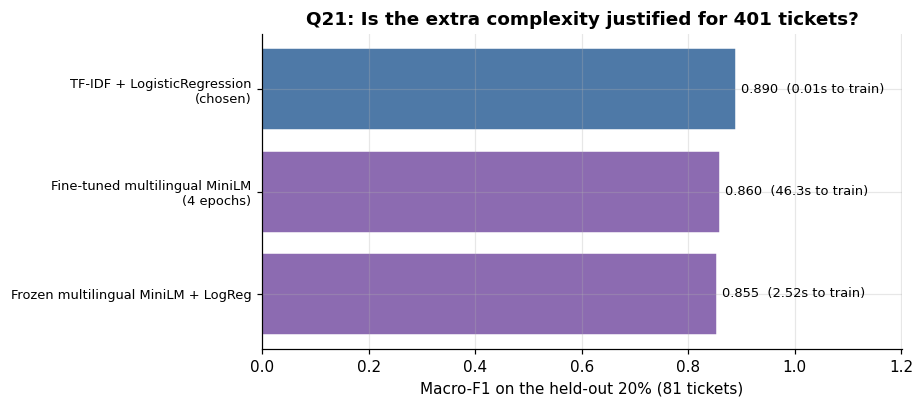

In [35]:
# Figure: final comparison.
fig, ax = plt.subplots(figsize=(8.5, 3.8))
o = cmp_tbl.sort_values("macro_F1")
cols = ["#4E79A7" if "TF-IDF" in i else "#8C6BB1" for i in o.index]
ax.barh(range(len(o)), o["macro_F1"], color=cols, edgecolor="white")
ax.set_yticks(range(len(o)))
ax.set_yticklabels([i.replace(" (", "\n(") for i in o.index], fontsize=8.5)
ax.set_xlabel("Macro-F1 on the held-out 20% (81 tickets)")
ax.set_title("Q21: Is the extra complexity justified for 401 tickets?", fontweight="bold")
for i, (v, t) in enumerate(zip(o["macro_F1"], o["train_time_s"])):
    ax.text(v + 0.01, i, f"{v:.3f}  ({t:g}s to train)", va="center", fontsize=8.5)
ax.set_xlim(0, max(1.0, o["macro_F1"].max() * 1.35))
save_fig("q21_transformer_comparison.png")
plt.show()

---
## Reproducibility: persist every headline number

In [36]:
RESULTS_PATH = os.path.join(OUT_DIR, "results.json")


def jsonable(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.ndarray,)):
        return o.tolist()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)


with open(RESULTS_PATH, "w") as fh:
    json.dump(results, fh, indent=1, default=jsonable)

print(f"Wrote {RESULTS_PATH} ({os.path.getsize(RESULTS_PATH)/1024:.0f} KB)")
print(f"Figures saved in {OUT_DIR}:")
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith(".png"):
        print(f"   {f}")
print(f"\nPredictions: {results['q17']['path']}")
print("\n--- notebook completed successfully ---")

Wrote ./assignment_outputs/results.json (39 KB)
Figures saved in ./assignment_outputs:
   q11_model_comparison.png
   q15_confusion_matrix.png
   q1_class_distribution.png
   q21_transformer_comparison.png

Predictions: /private/tmp/claude-501/-Volumes-Courses-fall-semester-2026-natural-language-processing-classifying-customer-complaint-tickets/41be29fc-3f25-4def-a80b-f581bf12a8f0/scratchpad/runfinal2/predictions.csv

--- notebook completed successfully ---


---
## AI-use declaration

See the assignment document for the required declaration.

## References

* Pedregosa, F. et al. (2011) 'Scikit-learn: Machine Learning in Python',
  *Journal of Machine Learning Research*, 12, pp. 2825–2830.
* Bird, S., Klein, E. and Loper, E. (2009) *Natural Language Processing with
  Python*. Sebastopol, CA: O'Reilly Media.
* Mikolov, T., Chen, K., Corrado, G. and Dean, J. (2013) 'Efficient Estimation
  of Word Representations in Vector Space', *arXiv:1301.3781*.
* Pennington, J., Socher, R. and Manning, C. (2014) 'GloVe: Global Vectors for
  Word Representation', *EMNLP 2014*, pp. 1532–1543.
* Řehůřek, R. and Sojka, P. (2010) 'Software Framework for Topic Modelling with
  Large Corpora', *Proceedings of the LREC 2010 Workshop on New Challenges for
  NLP Frameworks*, pp. 45–50.
* Reimers, N. and Gurevych, I. (2019) 'Sentence-BERT: Sentence Embeddings using
  Siamese BERT-Networks', *EMNLP-IJCNLP 2019*, pp. 3982–3992.
* Sanh, V., Debut, L., Chaumond, J. and Wolf, T. (2019) 'DistilBERT, a distilled
  version of BERT', *arXiv:1910.01108*.